Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
Selected device: cuda

CUDA available: True
GPU: Tesla T4
Output shape: torch.Size([1024, 1024])
GPU computation time: 0.0009882450103759766
GPU memory allocated: 20.12 MB
GPU verification PASSED!

Requirements.txt generated!
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
torch==2.14.1+cu130

Dataset extracted successfully!
Dataset location: /content/har/UCI HAR Dataset
Sensor channels: 9

Full training data: (7352, 128, 9)
Training labels: (7352,)
Test data: (2947, 128, 9)
Test labels: (2947,)
Training subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Testing subjects: [ 2  4  9 10 12 13 18 20 24]
HAR dataset loading verification PASSED!

Training shape: (5952, 128, 9)
Validation shape: (1400, 128, 9)
Testing shape: (2947, 128, 9)
Training subjects: [ 1  5  6  7  8 11 14 15 17 19 21 25 26 27 28 29 30

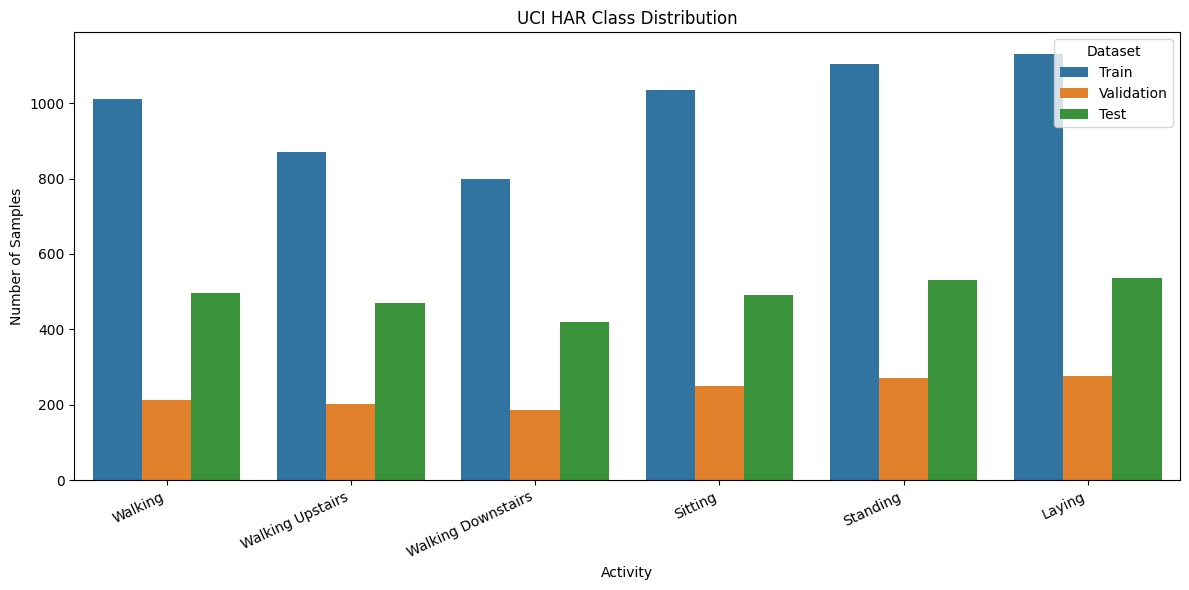

Class distribution saved: problem1/figures/har_class_distribution.png

Sequence length: 50
Train: (10000, 50, 2) (10000,)
Validation: (1000, 50, 2) (1000,)
Test: (1000, 50, 2) (1000,)

Sequence length: 100
Train: (10000, 100, 2) (10000,)
Validation: (1000, 100, 2) (1000,)
Test: (1000, 100, 2) (1000,)

Sequence length: 200
Train: (10000, 200, 2) (10000,)
Validation: (1000, 200, 2) (1000,)
Test: (1000, 200, 2) (1000,)

Sequence length: 400
Train: (10000, 400, 2) (10000,)
Validation: (1000, 400, 2) (1000,)
Test: (1000, 400, 2) (1000,)
T=50: PASSED
T=100: PASSED
T=200: PASSED
T=400: PASSED
ADDING PROBLEM VERIFICATION PASSED!
All Adding Problem datasets saved successfully!

========== FINAL TASK 1 SUMMARY ==========
Device: cuda

UCI HAR DATASET
Training samples: 5952
Validation samples: 1400
Testing samples: 2947
Sequence length: 128
Input channels: 9
Number of classes: 6
Validation subjects: [16  3 22 23]

ADDING PROBLEM DATASETS
T=50: (10000, 50, 2) (1000, 50, 2) (1000, 50, 2)
T=100: (10

In [4]:

# ============================================================
# PROBLEM 1 - TASK 1: DATA PIPELINES
# ===========================================================


# ============================================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================================

import sys
import os
import random
import time
import zipfile
import urllib.request
import importlib.metadata as metadata

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import sklearn


# ============================================================
# 2. REPRODUCIBILITY AND ENVIRONMENT SETUP
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

os.makedirs("problem1/data", exist_ok=True)
os.makedirs("problem1/figures", exist_ok=True)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("Selected device:", DEVICE)


# ============================================================
# 3. GPU AVAILABILITY AND PERFORMANCE VERIFICATION
# ============================================================

print("\nCUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.randn(1024, 1024, device=DEVICE)
    y = torch.randn(1024, 1024, device=DEVICE)

    torch.cuda.synchronize()

    start = time.time()

    z = torch.matmul(x, y)

    torch.cuda.synchronize()

    elapsed = time.time() - start

    print("Output shape:", z.shape)
    print("GPU computation time:", elapsed)

    print(
        "GPU memory allocated:",
        round(torch.cuda.memory_allocated() / 1024**2, 2),
        "MB"
    )

    assert z.device.type == "cuda"
    assert z.shape == (1024, 1024)

    print("GPU verification PASSED!")

else:

    print("GPU unavailable. Running on CPU.")


# ============================================================
# 4. GENERATE REQUIREMENTS.TXT
# ============================================================

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "torch"
]

with open("requirements.txt", "w") as f:

    for package in packages:

        version = metadata.version(package)

        f.write(f"{package}=={version}\n")

print("\nRequirements.txt generated!")

with open("requirements.txt", "r") as f:
    print(f.read())

# ============================================================
# 5. EXTRACT UPLOADED UCI HAR DATASET
# ============================================================

zip_path = "/content/UCI HAR Dataset.zip"

os.makedirs("/content/har", exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content/har")

dataset_root = Path("/content/har/UCI HAR Dataset")

assert dataset_root.exists(), "Dataset extraction failed!"

print("Dataset extracted successfully!")
print("Dataset location:", dataset_root)

# ============================================================
# 6. DEFINE HAR DATASET CONFIGURATION
# ============================================================

CHANNELS = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]

ACTIVITY_NAMES = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

INPUT_SIZE = 9
SEQ_LENGTH = 128
NUM_CLASSES = 6

print("Sensor channels:", len(CHANNELS))


# ============================================================
# 7. HAR DATASET LOADING FUNCTION
# ============================================================

def load_har_split(split):

    signal_dir = (
        dataset_root / split / "Inertial Signals"
    )

    signals = []

    # Load nine sensor channels

    for channel in CHANNELS:

        filename = (
            signal_dir / f"{channel}_{split}.txt"
        )

        data = np.loadtxt(
            filename,
            dtype=np.float32
        )

        signals.append(data)

    # Shape: (samples, 128, 9)

    X = np.stack(signals, axis=-1)

    # Load activity labels (convert 1-6 to 0-5)

    y = np.loadtxt(
        dataset_root / split / f"y_{split}.txt",
        dtype=np.int64
    ) - 1

    # Load subject IDs

    subjects = np.loadtxt(
        dataset_root / split / f"subject_{split}.txt",
        dtype=np.int64
    )

    assert X.shape[1:] == (SEQ_LENGTH, INPUT_SIZE)
    assert len(X) == len(y) == len(subjects)

    return X, y, subjects


# ============================================================
# 8. LOAD TRAINING AND TEST DATA
# ============================================================

X_full_train, y_full_train, train_subjects = (
    load_har_split("train")
)

X_test_raw, y_test, test_subjects = (
    load_har_split("test")
)

print("\nFull training data:", X_full_train.shape)
print("Training labels:", y_full_train.shape)

print("Test data:", X_test_raw.shape)
print("Test labels:", y_test.shape)

print("Training subjects:", np.unique(train_subjects))
print("Testing subjects:", np.unique(test_subjects))

assert X_full_train.shape == (7352, 128, 9)
assert X_test_raw.shape == (2947, 128, 9)

assert len(np.unique(train_subjects)) == 21
assert len(np.unique(test_subjects)) == 9

assert set(np.unique(train_subjects)).isdisjoint(
    set(np.unique(test_subjects))
)

print("HAR dataset loading verification PASSED!")


# ============================================================
# 9. SUBJECT-WISE TRAINING AND VALIDATION SPLIT
# ============================================================

def create_har_split(seed=SEED):

    rng = np.random.default_rng(seed)

    unique_subjects = np.unique(train_subjects)

    # Select four validation subjects

    validation_subjects = rng.choice(
        unique_subjects,
        size=4,
        replace=False
    )

    val_mask = np.isin(
        train_subjects,
        validation_subjects
    )

    train_mask = ~val_mask

    # Split training data

    X_train = X_full_train[train_mask].copy()
    y_train = y_full_train[train_mask].copy()

    X_val = X_full_train[val_mask].copy()
    y_val = y_full_train[val_mask].copy()

    # Calculate normalization statistics
    # Using training data only

    mean = X_train.mean(axis=(0, 1))
    std = X_train.std(axis=(0, 1))

    std = np.where(std < 1e-8, 1.0, std)

    # Normalize all datasets

    X_train = (X_train - mean) / std
    X_val = (X_val - mean) / std
    X_test = (X_test_raw.copy() - mean) / std

    return (
        X_train.astype(np.float32),
        y_train.astype(np.int64),

        X_val.astype(np.float32),
        y_val.astype(np.int64),

        X_test.astype(np.float32),
        y_test.copy().astype(np.int64),

        mean.astype(np.float32),
        std.astype(np.float32),

        validation_subjects
    )


(
    X_train, y_train,
    X_val, y_val,
    X_test, y_test_processed,
    har_mean, har_std,
    validation_subjects
) = create_har_split(SEED)


# ============================================================
# 10. VERIFY SUBJECT-WISE SPLIT
# ============================================================

training_subjects = np.unique(
    train_subjects[
        ~np.isin(train_subjects, validation_subjects)
    ]
)

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("Training subjects:", training_subjects)
print("Validation subjects:", validation_subjects)

assert len(training_subjects) == 17
assert len(validation_subjects) == 4

assert set(training_subjects).isdisjoint(
    set(validation_subjects)
)

assert set(np.unique(train_subjects)).isdisjoint(
    set(np.unique(test_subjects))
)

print("SUBJECT-WISE SPLIT VERIFICATION PASSED!")


# ============================================================
# 11. VERIFY DATA SHAPES AND NORMALIZATION
# ============================================================

assert X_train.shape[1:] == (128, 9)
assert X_val.shape[1:] == (128, 9)
assert X_test.shape == (2947, 128, 9)

assert y_train.shape == (len(X_train),)
assert y_val.shape == (len(X_val),)
assert y_test_processed.shape == (2947,)

assert set(np.unique(y_train)).issubset(set(range(6)))
assert set(np.unique(y_val)).issubset(set(range(6)))
assert set(np.unique(y_test_processed)).issubset(set(range(6)))

train_mean_check = X_train.mean(axis=(0, 1))
train_std_check = X_train.std(axis=(0, 1))

print("\nTraining mean:", train_mean_check)
print("Training standard deviation:", train_std_check)

assert np.allclose(
    train_mean_check, 0, atol=1e-3
)

assert np.allclose(
    train_std_check, 1, atol=1e-3
)

assert np.all(np.isfinite(X_train))
assert np.all(np.isfinite(X_val))
assert np.all(np.isfinite(X_test))

print("NORMALIZATION VERIFICATION PASSED!")


# ============================================================
# 12. CLASS DISTRIBUTION VISUALIZATION
# ============================================================

def plot_class_distribution(
    y_train,
    y_val,
    y_test,
    save_path="problem1/figures/har_class_distribution.png"
):

    datasets = {
        "Train": y_train,
        "Validation": y_val,
        "Test": y_test
    }

    counts = []

    for split_name, labels in datasets.items():

        for class_id in range(NUM_CLASSES):

            counts.append({
                "Dataset": split_name,
                "Activity": ACTIVITY_NAMES[class_id],
                "Count": np.sum(labels == class_id)
            })

    df = pd.DataFrame(counts)

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=df,
        x="Activity",
        y="Count",
        hue="Dataset"
    )

    plt.title("UCI HAR Class Distribution")
    plt.xlabel("Activity")
    plt.ylabel("Number of Samples")

    plt.xticks(rotation=25, ha="right")

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Class distribution saved:", save_path)


plot_class_distribution(
    y_train,
    y_val,
    y_test_processed
)


# ============================================================
# 13. ADDING PROBLEM DATASET GENERATOR
# ============================================================

def make_adding(n, T, seed):

    rng = np.random.default_rng(seed)

    x = np.zeros(
        (n, T, 2),
        dtype=np.float32
    )

    # First channel: random values

    x[:, :, 0] = rng.random((n, T))

    # Select two marker positions

    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)

    # Second channel: markers

    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1

    # Target: sum of marked values

    y = (
        x[np.arange(n), i1, 0]
        +
        x[np.arange(n), i2, 0]
    )

    return x, y.astype(np.float32)


# ============================================================
# 14. GENERATE FOUR ADDING PROBLEM DATASETS
# ============================================================

ADDING_LENGTHS = [50, 100, 200, 400]

adding_data = {}

for T in ADDING_LENGTHS:

    X_tr, y_tr = make_adding(10000, T, 0)

    X_val_add, y_val_add = make_adding(1000, T, 1)

    X_te, y_te = make_adding(1000, T, 2)

    adding_data[T] = {
        "train": (X_tr, y_tr),
        "val": (X_val_add, y_val_add),
        "test": (X_te, y_te)
    }

    print(f"\nSequence length: {T}")

    print("Train:", X_tr.shape, y_tr.shape)
    print("Validation:", X_val_add.shape, y_val_add.shape)
    print("Test:", X_te.shape, y_te.shape)


# ============================================================
# 15. VERIFY ADDING PROBLEM GENERATOR
# ============================================================

def check_adding(T):

    X, y = make_adding(1000, T, seed=SEED)

    markers = X[:, :, 1]

    # Exactly two markers

    assert np.all(markers.sum(axis=1) == 2)

    # One marker in each half

    assert np.all(
        markers[:, :T // 2].sum(axis=1) == 1
    )

    assert np.all(
        markers[:, T // 2:].sum(axis=1) == 1
    )

    # Verify target calculation

    expected = (
        X[:, :, 0] * markers
    ).sum(axis=1)

    assert np.allclose(
        y, expected, atol=1e-6
    )

    print(f"T={T}: PASSED")


for T in ADDING_LENGTHS:
    check_adding(T)

print("ADDING PROBLEM VERIFICATION PASSED!")


# ============================================================
# 16. SAVE ADDING PROBLEM DATASETS
# ============================================================

for T, data in adding_data.items():

    np.savez_compressed(
        f"problem1/data/adding_T{T}.npz",

        X_train=data["train"][0],
        y_train=data["train"][1],

        X_val=data["val"][0],
        y_val=data["val"][1],

        X_test=data["test"][0],
        y_test=data["test"][1]
    )

print("All Adding Problem datasets saved successfully!")


# ============================================================
# 17. FINAL DATA PIPELINE SUMMARY
# ============================================================

print("\n========== FINAL TASK 1 SUMMARY ==========")

print("Device:", DEVICE)

print("\nUCI HAR DATASET")

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("Sequence length:", SEQ_LENGTH)
print("Input channels:", INPUT_SIZE)
print("Number of classes:", NUM_CLASSES)

print("Validation subjects:", validation_subjects)

print("\nADDING PROBLEM DATASETS")

for T in ADDING_LENGTHS:

    print(
        f"T={T}:",
        adding_data[T]["train"][0].shape,
        adding_data[T]["val"][0].shape,
        adding_data[T]["test"][0].shape
    )


In [3]:
#Task 2
#Vanilla RNN
import torch
import torch.nn as nn
import numpy as np

# Device
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Model configuration
INPUT_SIZE = 9
HIDDEN_SIZE = 64
BATCH_SIZE = 32
SEQ_LENGTH = 128

import random
random.seed(0); np.random.seed(0); torch.manual_seed(0)

# Reference RNN
reference_rnn = nn.RNN(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=1,
    nonlinearity="tanh",
    batch_first=True
).to(DEVICE)

print(reference_rnn)

# Generate random input - Random input sequence
x = torch.randn(
    BATCH_SIZE,
    SEQ_LENGTH,
    INPUT_SIZE,
    device=DEVICE
)

# Initial hidden state
h0 = torch.zeros(
    1,
    BATCH_SIZE,
    HIDDEN_SIZE,
    device=DEVICE
)

print("Input shape:", x.shape)
print("Initial hidden shape:", h0.shape)

#Execute the reference RNN
with torch.no_grad():

    output, hn = reference_rnn(x, h0)

print("Output shape:", output.shape)
print("Final hidden shape:", hn.shape)

assert output.shape == (32, 128, 64)
assert hn.shape == (1, 32, 64)

print("Reference RNN test passed!")

#Inspect the weights
for name, parameter in reference_rnn.named_parameters():

    print(
        name,
        parameter.shape,
        parameter.numel()
    )

total_params = sum(
    p.numel()
    for p in reference_rnn.parameters()
)
# P= hd+h^2+2h
#P= 64(9)+64(64)+2(64)
#P=4800

print("\nTotal parameters:", total_params)

assert total_params == 4800
# Extract weights from reference RNN
W_ih = reference_rnn.weight_ih_l0
W_hh = reference_rnn.weight_hh_l0

b_ih = reference_rnn.bias_ih_l0
b_hh = reference_rnn.bias_hh_l0

# Select the first time step
# Shape: (32, 9)
x_t = x[:, 0, :]

# Initial previous hidden state
# Shape: (32, 64)
h_prev = torch.zeros(
    BATCH_SIZE,
    HIDDEN_SIZE,
    device=DEVICE
)

# Vanilla RNN equation
h_t = torch.tanh(
    torch.matmul(x_t, W_ih.T)
    + b_ih
    + torch.matmul(h_prev, W_hh.T)
    + b_hh
)

print("Current input shape:", x_t.shape)
print("Previous hidden shape:", h_prev.shape)
print("New hidden state shape:", h_t.shape)

assert h_t.shape == (32, 64)

print("One-step RNN calculation passed!")

#Compare with PyTorch
with torch.no_grad():

    reference_output, _ = reference_rnn(x, h0)

    expected_h_t = reference_output[:, 0, :]

difference = torch.max(
    torch.abs(h_t - expected_h_t)
)

print("Maximum absolute difference:", difference.item())

assert torch.allclose(
    h_t,
    expected_h_t,
    atol=1e-5,
    rtol=1e-5
)

print("Manual RNN matches PyTorch reference!")


class MyRNNCell(nn.Module):

    def __init__(self, input_size, hidden_size):

        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Input-to-hidden transformation
        self.weight_ih = nn.Parameter(
            torch.empty(hidden_size, input_size)
        )

        # Hidden-to-hidden transformation
        self.weight_hh = nn.Parameter(
            torch.empty(hidden_size, hidden_size)
        )

        # Two bias vectors to match PyTorch nn.RNN
        self.bias_ih = nn.Parameter(
            torch.empty(hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.empty(hidden_size)
        )

        self.reset_parameters()

    def reset_parameters(self):

        nn.init.uniform_(
            self.weight_ih,
            -0.1,
            0.1
        )

        nn.init.uniform_(
            self.weight_hh,
            -0.1,
            0.1
        )

        nn.init.zeros_(self.bias_ih)
        nn.init.zeros_(self.bias_hh)

    def forward(self, x_t, h_prev):

        # x_t: (batch_size, input_size)
        # h_prev: (batch_size, hidden_size)

        h_t = torch.tanh(
            torch.matmul(x_t, self.weight_ih.T)
            + self.bias_ih
            + torch.matmul(h_prev, self.weight_hh.T)
            + self.bias_hh
        )

        # h_t: (batch_size, hidden_size)
        return h_t


class MyRNN(nn.Module):

    def __init__(self, input_size, hidden_size):

        super().__init__()

        self.hidden_size = hidden_size

        self.cell = MyRNNCell(
            input_size,
            hidden_size
        )

    def forward(self, x, h0=None):

        # x: (batch_size, sequence_length, input_size)

        batch_size, seq_length, _ = x.shape

        if h0 is None:
            h = torch.zeros(
                batch_size,
                self.hidden_size,
                device=x.device,
                dtype=x.dtype
            )
        else:
            # h0: (1, batch_size, hidden_size)
            h = h0.squeeze(0)

        outputs = []

        for t in range(seq_length):

            # Extract current time step
            x_t = x[:, t, :]

            # Update hidden state
            h = self.cell(x_t, h)

            outputs.append(h.unsqueeze(1))

        # Combine all time-step outputs
        output = torch.cat(outputs, dim=1)

        # Final hidden state
        hn = h.unsqueeze(0)

        return output, hn


my_rnn = MyRNN(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE
).to(DEVICE)

print(my_rnn)

#Copy PyTorch reference weights
with torch.no_grad():

    my_rnn.cell.weight_ih.copy_(
        reference_rnn.weight_ih_l0
    )

    my_rnn.cell.weight_hh.copy_(
        reference_rnn.weight_hh_l0
    )

    my_rnn.cell.bias_ih.copy_(
        reference_rnn.bias_ih_l0
    )

    my_rnn.cell.bias_hh.copy_(
        reference_rnn.bias_hh_l0
    )

print("Reference weights copied successfully!")
#Compare custom RNN with PyTorch

my_rnn.eval()
reference_rnn.eval()

with torch.no_grad():

    custom_output, custom_hidden = my_rnn(x, h0)

    reference_output, reference_hidden = reference_rnn(x, h0)

# Calculate maximum differences
output_diff = torch.max(
    torch.abs(custom_output - reference_output)
)

hidden_diff = torch.max(
    torch.abs(custom_hidden - reference_hidden)
)

print("Custom output shape:", custom_output.shape)
print("Reference output shape:", reference_output.shape)

print("Custom hidden shape:", custom_hidden.shape)
print("Reference hidden shape:", reference_hidden.shape)

print("Maximum output difference:", output_diff.item())
print("Maximum hidden difference:", hidden_diff.item())

assert torch.allclose(
    custom_output,
    reference_output,
    atol=1e-5,
    rtol=1e-5
)

assert torch.allclose(
    custom_hidden,
    reference_hidden,
    atol=1e-5,
    rtol=1e-5
)

print("\nCUSTOM RNN VERIFICATION PASSED!")

h0_rand = torch.randn(1, BATCH_SIZE, HIDDEN_SIZE, device=DEVICE)
with torch.no_grad():
    o1, n1 = my_rnn(x, h0_rand)
    o2, n2 = reference_rnn(x, h0_rand)
assert torch.allclose(o1, o2, atol=1e-5, rtol=1e-5)
assert torch.allclose(n1, n2, atol=1e-5, rtol=1e-5)
print("Non-zero h0 test passed!")

#Verify parameter count

custom_params = sum(
    p.numel()
    for p in my_rnn.parameters()
)

reference_params = sum(
    p.numel()
    for p in reference_rnn.parameters()
)

print("Custom RNN parameters:", custom_params)
print("Reference RNN parameters:", reference_params)

# Textbook count (one bias): h*d + h*h + h = 576 + 4096 + 64 = 4736
# PyTorch and MyRNN keep b_ih and b_hh separately -> extra h = 64 -> 4800
textbook_params = HIDDEN_SIZE*INPUT_SIZE + HIDDEN_SIZE*HIDDEN_SIZE + HIDDEN_SIZE
assert textbook_params == 4736
assert custom_params == textbook_params + HIDDEN_SIZE
assert reference_params == textbook_params + HIDDEN_SIZE

print("Parameter count verification PASSED!")



import os
import pandas as pd

# Create folder if it does not exist
os.makedirs("problem1", exist_ok=True)

# Store RNN verification results
rnn_verification = pd.DataFrame([{
    "model": "Vanilla RNN",
    "input_size": 9,
    "hidden_size": 64,
    "custom_params": custom_params,
    "reference_params": reference_params,
    "max_output_difference": output_diff.item(),
    "max_hidden_difference": hidden_diff.item(),
    "verification": "PASS"
}])

# Save CSV
rnn_verification.to_csv("rnn_verification.csv", index=False)

print(rnn_verification.to_string(index=False))
print("\nRNN verification results saved successfully!")

#LSTM

import torch
import torch.nn as nn
import os
import pandas as pd

import random, numpy as np
random.seed(0); np.random.seed(0); torch.manual_seed(0)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

INPUT_SIZE = 9
HIDDEN_SIZE = 64
BATCH_SIZE = 32
SEQ_LENGTH = 128

# Reference LSTM
reference_lstm = nn.LSTM(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=1,
    batch_first=True
).to(DEVICE)

# Random input
x = torch.randn(
    BATCH_SIZE,
    SEQ_LENGTH,
    INPUT_SIZE,
    device=DEVICE
)

# Zero initial hidden and cell states
h0 = torch.zeros(
    1, BATCH_SIZE, HIDDEN_SIZE,
    device=DEVICE
)

c0 = torch.zeros(
    1, BATCH_SIZE, HIDDEN_SIZE,
    device=DEVICE
)

print(reference_lstm)
print("Input shape:", x.shape)
print("Initial hidden shape:", h0.shape)
print("Initial cell shape:", c0.shape)



class MyLSTMCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Four gates: input, forget, candidate, output
        self.weight_ih = nn.Parameter(
            torch.empty(4 * hidden_size, input_size)
        )

        self.weight_hh = nn.Parameter(
            torch.empty(4 * hidden_size, hidden_size)
        )

        self.bias_ih = nn.Parameter(
            torch.empty(4 * hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.empty(4 * hidden_size)
        )

        self.reset_parameters()

    def reset_parameters(self):

        for parameter in self.parameters():
            nn.init.uniform_(parameter, -0.1, 0.1)

    def forward(self, x_t, states):

        # x_t: (batch_size, input_size)
        # h_prev: (batch_size, hidden_size)
        # c_prev: (batch_size, hidden_size)

        h_prev, c_prev = states

        # Combined gate calculation
        # z: (batch_size, 4 * hidden_size)
        z = (
            torch.matmul(x_t, self.weight_ih.T)
            + self.bias_ih
            + torch.matmul(h_prev, self.weight_hh.T)
            + self.bias_hh
        )

        # PyTorch gate order: input, forget, candidate, output
        i, f, g, o = z.chunk(4, dim=1)

        # Gate activations
        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)

        # New cell state
        c_t = f * c_prev + i * g

        # New hidden state
        h_t = o * torch.tanh(c_t)

        return h_t, c_t

class MyLSTM(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.hidden_size = hidden_size

        self.cell = MyLSTMCell(
            input_size,
            hidden_size
        )

    def forward(self, x, states=None):

        # x: (batch_size, sequence_length, input_size)

        batch_size, seq_length, _ = x.shape

        if states is None:

            h = torch.zeros(
                batch_size,
                self.hidden_size,
                device=x.device,
                dtype=x.dtype
            )

            c = torch.zeros(
                batch_size,
                self.hidden_size,
                device=x.device,
                dtype=x.dtype
            )

        else:

            h0, c0 = states

            # Convert (1, batch, hidden) to (batch, hidden)
            h = h0.squeeze(0)
            c = c0.squeeze(0)

        outputs = []

        for t in range(seq_length):

            # Current input: (batch_size, input_size)
            x_t = x[:, t, :]

            # Calculate next hidden and cell states
            h, c = self.cell(x_t, (h, c))

            outputs.append(h.unsqueeze(1))

        # (batch_size, sequence_length, hidden_size)
        output = torch.cat(outputs, dim=1)

        # Return states in PyTorch format
        hn = h.unsqueeze(0)
        cn = c.unsqueeze(0)

        return output, (hn, cn)

my_lstm = MyLSTM(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE
).to(DEVICE)

print(my_lstm)

with torch.no_grad():

    my_lstm.cell.weight_ih.copy_(
        reference_lstm.weight_ih_l0
    )

    my_lstm.cell.weight_hh.copy_(
        reference_lstm.weight_hh_l0
    )

    my_lstm.cell.bias_ih.copy_(
        reference_lstm.bias_ih_l0
    )

    my_lstm.cell.bias_hh.copy_(
        reference_lstm.bias_hh_l0
    )

print("LSTM reference weights copied successfully!")


my_lstm.eval()
reference_lstm.eval()

with torch.no_grad():

    custom_output, (custom_hn, custom_cn) = my_lstm(
        x, (h0, c0)
    )

    reference_output, (reference_hn, reference_cn) = reference_lstm(
        x, (h0, c0)
    )

output_diff = torch.max(
    torch.abs(custom_output - reference_output)
)

hidden_diff = torch.max(
    torch.abs(custom_hn - reference_hn)
)

cell_diff = torch.max(
    torch.abs(custom_cn - reference_cn)
)

print("Custom output shape:", custom_output.shape)
print("Reference output shape:", reference_output.shape)

print("Maximum output difference:", output_diff.item())
print("Maximum hidden difference:", hidden_diff.item())
print("Maximum cell difference:", cell_diff.item())

assert torch.allclose(
    custom_output, reference_output,
    atol=1e-5, rtol=1e-5
)

assert torch.allclose(
    custom_hn, reference_hn,
    atol=1e-5, rtol=1e-5
)

assert torch.allclose(
    custom_cn, reference_cn,
    atol=1e-5, rtol=1e-5
)

print("ZERO-STATE LSTM VERIFICATION PASSED!")


# Random initial hidden and cell states
random_h0 = torch.randn(
    1, BATCH_SIZE, HIDDEN_SIZE,
    device=DEVICE
)

random_c0 = torch.randn(
    1, BATCH_SIZE, HIDDEN_SIZE,
    device=DEVICE
)

with torch.no_grad():

    custom_output_random, (custom_h_random, custom_c_random) = my_lstm(
        x, (random_h0, random_c0)
    )

    reference_output_random, (reference_h_random, reference_c_random) = reference_lstm(
        x, (random_h0, random_c0)
    )

random_output_diff = (
    custom_output_random - reference_output_random
).abs().max()

random_hidden_diff = (
    custom_h_random - reference_h_random
).abs().max()

random_cell_diff = (
    custom_c_random - reference_c_random
).abs().max()

print("Random-state output difference:", random_output_diff.item())
print("Random-state hidden difference:", random_hidden_diff.item())
print("Random-state cell difference:", random_cell_diff.item())

assert torch.allclose(
    custom_output_random,
    reference_output_random,
    atol=1e-5, rtol=1e-5
)

assert torch.allclose(
    custom_h_random,
    reference_h_random,
    atol=1e-5, rtol=1e-5
)

assert torch.allclose(
    custom_c_random,
    reference_c_random,
    atol=1e-5, rtol=1e-5
)

print("RANDOM-STATE LSTM VERIFICATION PASSED!")


custom_lstm_params = sum(
    p.numel() for p in my_lstm.parameters()
)

reference_lstm_params = sum(
    p.numel() for p in reference_lstm.parameters()
)

print("Custom LSTM parameters:", custom_lstm_params)
print("Reference LSTM parameters:", reference_lstm_params)


# Textbook count (one bias): 4 * (h*d + h*h + h) = 4 * (576 + 4096 + 64) = 18944
# PyTorch and MyLSTM keep b_ih and b_hh separately -> extra 4h = 256 -> 19200
textbook_lstm_params = 4 * (HIDDEN_SIZE*INPUT_SIZE + HIDDEN_SIZE*HIDDEN_SIZE + HIDDEN_SIZE)
assert textbook_lstm_params == 18944
assert custom_lstm_params == textbook_lstm_params + 4*HIDDEN_SIZE
assert reference_lstm_params == textbook_lstm_params + 4*HIDDEN_SIZE

print("LSTM PARAMETER VERIFICATION PASSED!")



lstm_results = pd.DataFrame([{
    "model": "LSTM",
    "input_size": INPUT_SIZE,
    "hidden_size": HIDDEN_SIZE,
    "custom_params": custom_lstm_params,
    "reference_params": reference_lstm_params,
    "zero_output_difference": output_diff.item(),
    "zero_hidden_difference": hidden_diff.item(),
    "zero_cell_difference": cell_diff.item(),
    "random_output_difference": random_output_diff.item(),
    "random_hidden_difference": random_hidden_diff.item(),
    "random_cell_difference": random_cell_diff.item(),
    "verification": "PASS"
}])

lstm_results.to_csv(
    "problem1/lstm_verification.csv",
    index=False
)

print(lstm_results.to_string(index=False))
print("\nLSTM verification results saved!")


RNN(9, 64, batch_first=True)
Input shape: torch.Size([32, 128, 9])
Initial hidden shape: torch.Size([1, 32, 64])
Output shape: torch.Size([32, 128, 64])
Final hidden shape: torch.Size([1, 32, 64])
Reference RNN test passed!
weight_ih_l0 torch.Size([64, 9]) 576
weight_hh_l0 torch.Size([64, 64]) 4096
bias_ih_l0 torch.Size([64]) 64
bias_hh_l0 torch.Size([64]) 64

Total parameters: 4800
Current input shape: torch.Size([32, 9])
Previous hidden shape: torch.Size([32, 64])
New hidden state shape: torch.Size([32, 64])
One-step RNN calculation passed!
Maximum absolute difference: 5.364418029785156e-06
Manual RNN matches PyTorch reference!
MyRNN(
  (cell): MyRNNCell()
)
Reference weights copied successfully!
Custom output shape: torch.Size([32, 128, 64])
Reference output shape: torch.Size([32, 128, 64])
Custom hidden shape: torch.Size([1, 32, 64])
Reference hidden shape: torch.Size([1, 32, 64])
Maximum output difference: 7.212162017822266e-06
Maximum hidden difference: 6.258487701416016e-06

CUS

In [4]:
# ===== Problem 1, Task 2: GRU =====
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

random.seed(0); np.random.seed(0); torch.manual_seed(0)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

INPUT_SIZE = 9
HIDDEN_SIZE = 64
BATCH_SIZE = 32
SEQ_LENGTH = 128

# PyTorch reference GRU
reference_gru = nn.GRU(INPUT_SIZE, HIDDEN_SIZE, num_layers=1, batch_first=True).to(DEVICE)

x = torch.randn(BATCH_SIZE, SEQ_LENGTH, INPUT_SIZE, device=DEVICE)
h0 = torch.zeros(1, BATCH_SIZE, HIDDEN_SIZE, device=DEVICE)


class MyGRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_size, self.hidden_size = input_size, hidden_size
        # Three gates stacked in PyTorch order: reset, update, new
        self.weight_ih = nn.Parameter(torch.empty(3 * hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(3 * hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(3 * hidden_size))
        self.bias_hh = nn.Parameter(torch.empty(3 * hidden_size))
        self.reset_parameters()

    def reset_parameters(self):
        for p in self.parameters():
            nn.init.uniform_(p, -0.1, 0.1)

    def forward(self, x_t, h_prev):
        # x_t: (B, d), h_prev: (B, h)
        gi = torch.matmul(x_t, self.weight_ih.T) + self.bias_ih       # (B, 3h)
        gh = torch.matmul(h_prev, self.weight_hh.T) + self.bias_hh    # (B, 3h)
        gi_r, gi_z, gi_n = gi.chunk(3, dim=1)                         # each (B, h)
        gh_r, gh_z, gh_n = gh.chunk(3, dim=1)
        r = torch.sigmoid(gi_r + gh_r)                                # reset gate
        z = torch.sigmoid(gi_z + gh_z)                                # update gate
        n = torch.tanh(gi_n + r * gh_n)                               # reset multiplies the whole hidden term, bias included
        return (1 - z) * n + z * h_prev                               # (B, h)


class MyGRU(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.cell = MyGRUCell(input_size, hidden_size)

    def forward(self, x, h0=None):
        B, T, _ = x.shape                                             # x: (B, T, d)
        h = (torch.zeros(B, self.hidden_size, device=x.device, dtype=x.dtype)
             if h0 is None else h0.squeeze(0))                        # (B, h)
        outputs = []
        for t in range(T):
            h = self.cell(x[:, t, :], h)
            outputs.append(h.unsqueeze(1))                            # (B, 1, h)
        return torch.cat(outputs, dim=1), h.unsqueeze(0)              # (B, T, h), (1, B, h)


my_gru = MyGRU(INPUT_SIZE, HIDDEN_SIZE).to(DEVICE)

# Copy weights from the reference layer
with torch.no_grad():
    my_gru.cell.weight_ih.copy_(reference_gru.weight_ih_l0)
    my_gru.cell.weight_hh.copy_(reference_gru.weight_hh_l0)
    my_gru.cell.bias_ih.copy_(reference_gru.bias_ih_l0)
    my_gru.cell.bias_hh.copy_(reference_gru.bias_hh_l0)

my_gru.eval(); reference_gru.eval()

# ----- zero initial state -----
with torch.no_grad():
    c_out, c_hn = my_gru(x, h0)
    r_out, r_hn = reference_gru(x, h0)
output_diff = (c_out - r_out).abs().max()
hidden_diff = (c_hn - r_hn).abs().max()
print("Zero-state output diff:", output_diff.item(), "| hidden diff:", hidden_diff.item())
assert torch.allclose(c_out, r_out, atol=1e-5, rtol=1e-5)
assert torch.allclose(c_hn, r_hn, atol=1e-5, rtol=1e-5)
print("ZERO-STATE GRU VERIFICATION PASSED!")

# ----- random initial state -----
random_h0 = torch.randn(1, BATCH_SIZE, HIDDEN_SIZE, device=DEVICE)
with torch.no_grad():
    c_out_r, c_hn_r = my_gru(x, random_h0)
    r_out_r, r_hn_r = reference_gru(x, random_h0)
random_output_diff = (c_out_r - r_out_r).abs().max()
random_hidden_diff = (c_hn_r - r_hn_r).abs().max()
print("Random-state output diff:", random_output_diff.item(), "| hidden diff:", random_hidden_diff.item())
assert torch.allclose(c_out_r, r_out_r, atol=1e-5, rtol=1e-5)
assert torch.allclose(c_hn_r, r_hn_r, atol=1e-5, rtol=1e-5)
print("RANDOM-STATE GRU VERIFICATION PASSED!")

# ----- parameter counts -----
custom_gru_params = sum(p.numel() for p in my_gru.parameters())
reference_gru_params = sum(p.numel() for p in reference_gru.parameters())
print("Custom GRU parameters:", custom_gru_params, "| Reference:", reference_gru_params)

# Textbook count (one bias): 3 * (h*d + h*h + h) = 3 * (576 + 4096 + 64) = 14208
# PyTorch and MyGRU keep b_ih and b_hh separately -> extra 3h = 192 -> 14400
textbook_gru_params = 3 * (HIDDEN_SIZE * INPUT_SIZE + HIDDEN_SIZE * HIDDEN_SIZE + HIDDEN_SIZE)
assert textbook_gru_params == 14208
assert custom_gru_params == textbook_gru_params + 3 * HIDDEN_SIZE == 14400
assert reference_gru_params == textbook_gru_params + 3 * HIDDEN_SIZE
print("GRU PARAMETER VERIFICATION PASSED!")

# ----- save verification table (path relative to the notebook's folder, problem1/) -----
gru_results = pd.DataFrame([{
    "model": "GRU", "input_size": INPUT_SIZE, "hidden_size": HIDDEN_SIZE,
    "textbook_params": textbook_gru_params,
    "custom_params": custom_gru_params, "reference_params": reference_gru_params,
    "zero_output_difference": output_diff.item(), "zero_hidden_difference": hidden_diff.item(),
    "random_output_difference": random_output_diff.item(),
    "random_hidden_difference": random_hidden_diff.item(),
    "verification": "PASS"
}])
gru_results.to_csv("gru_verification.csv", index=False)
print(gru_results.to_string(index=False))

Zero-state output diff: 4.470348358154297e-06 | hidden diff: 3.337860107421875e-06
ZERO-STATE GRU VERIFICATION PASSED!
Random-state output diff: 5.0067901611328125e-06 | hidden diff: 3.337860107421875e-06
RANDOM-STATE GRU VERIFICATION PASSED!
Custom GRU parameters: 14400 | Reference: 14400
GRU PARAMETER VERIFICATION PASSED!
model  input_size  hidden_size  textbook_params  custom_params  reference_params  zero_output_difference  zero_hidden_difference  random_output_difference  random_hidden_difference verification
  GRU           9           64            14208          14400             14400                0.000004                0.000003                  0.000005                  0.000003         PASS


Device: cuda
Original labels: [0 1 2 3 4 5]
Train labels: [0 1 2 3 4 5]
Validation labels: [0 1 2 3 4 5]
Test labels: [0 1 2 3 4 5]
Original labels: [0 1 2 3 4 5]
Train labels: [0 1 2 3 4 5]
Validation labels: [0 1 2 3 4 5]
Test labels: [0 1 2 3 4 5]
Original labels: [0 1 2 3 4 5]
Train labels: [0 1 2 3 4 5]
Validation labels: [0 1 2 3 4 5]
Test labels: [0 1 2 3 4 5]

All HAR data checks passed.

Training RNN | Seed 0
Original labels: [0 1 2 3 4 5]
Train labels: [0 1 2 3 4 5]
Validation labels: [0 1 2 3 4 5]
Test labels: [0 1 2 3 4 5]
Epoch 01/20 | Train Loss: 1.2784 | Val Loss: 1.3962 | Time: 1.99s
Epoch 02/20 | Train Loss: 1.0571 | Val Loss: 1.2885 | Time: 0.23s
Epoch 03/20 | Train Loss: 1.2552 | Val Loss: 1.1293 | Time: 0.23s
Epoch 04/20 | Train Loss: 1.0685 | Val Loss: 1.0437 | Time: 0.24s
Epoch 05/20 | Train Loss: 0.9160 | Val Loss: 0.9399 | Time: 0.23s
Epoch 06/20 | Train Loss: 0.7406 | Val Loss: 0.8256 | Time: 0.23s
Epoch 07/20 | Train Loss: 0.6010 | Val Loss: 0.6828 | Time: 0.2

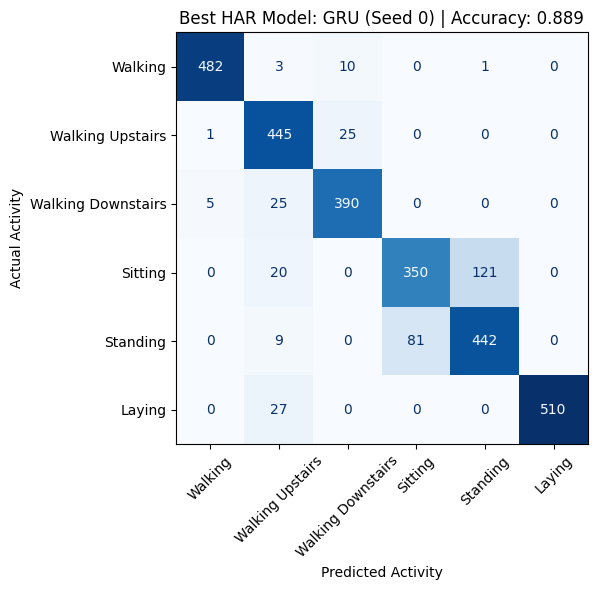


Total runs: 9
Results: results.csv
Summary: har_summary.csv
Figure: figures/har_confusion_matrix.png


In [5]:

# ===== Task 3: HAR classification with RNN / LSTM / GRU =====

import os
import time
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

assert "create_har_split" in globals(), "Run the HAR data cell first."

HIDDEN = 64
EPOCHS = 20
BATCH = 64
LR = 1e-3

HAR_SEEDS = (0, 1, 2)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

ACTIVITY_NAMES = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

RESULTS_CSV = "results.csv"
os.makedirs("figures", exist_ok=True)

COLS = [
    "problem", "model", "seed", "seq_len",
    "test_acc", "macro_f1", "test_mse",
    "params", "sec_per_epoch",
    "val_loss_nats", "bits_per_char", "notes"
]

print("Device:", DEVICE)


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


# ============================================================
# 3. LABEL VALIDATION
# ============================================================

def prepare_labels(ytr, yva, yte):

    ytr = np.asarray(ytr).reshape(-1).astype(np.int64)
    yva = np.asarray(yva).reshape(-1).astype(np.int64)
    yte = np.asarray(yte).reshape(-1).astype(np.int64)

    unique = np.unique(
        np.concatenate([ytr, yva, yte])
    )

    print("Original labels:", unique)

    # Convert original UCI labels 1-6 to 0-5.
    # Do not subtract if labels are already 0-5.

    if np.array_equal(unique, np.arange(1, 7)):
        ytr -= 1
        yva -= 1
        yte -= 1

    elif not np.array_equal(unique, np.arange(0, 6)):
        raise ValueError(
            f"Unexpected HAR labels: {unique}"
        )

    for name, y in [
        ("Train", ytr),
        ("Validation", yva),
        ("Test", yte)
    ]:
        assert y.min() >= 0, f"{name}: negative labels"
        assert y.max() < 6, f"{name}: labels above 5"

        print(name, "labels:", np.unique(y))

    return ytr, yva, yte


# ============================================================
# 4. PRE-CHECK ALL THREE SPLITS
# ============================================================

for seed in HAR_SEEDS:

    out = create_har_split(seed)

    ytr, yva, yte = prepare_labels(
        out[1], out[3], out[5]
    )

    assert out[0].shape[1:] == (128, 9)
    assert out[2].shape[1:] == (128, 9)
    assert out[4].shape[1:] == (128, 9)

print("\nAll HAR data checks passed.")


# ============================================================
# 5. CLEAN PREVIOUS HAR RESULTS
# ============================================================

if os.path.exists(RESULTS_CSV):

    old = pd.read_csv(RESULTS_CSV)

    old = old[old["problem"] != "P1_HAR"]

    old.to_csv(RESULTS_CSV, index=False)


def log_row(**kw):

    row = {
        c: kw.get(c, "")
        for c in COLS
    }

    pd.DataFrame([row]).to_csv(
        RESULTS_CSV,
        mode="a",
        index=False,
        header=not os.path.exists(RESULTS_CSV)
    )


# ============================================================
# 6. RECURRENT CLASSIFIER
# ============================================================

class RecurrentClassifier(nn.Module):

    def __init__(self, kind, d_in, hidden, n_classes):

        super().__init__()

        cls = {
            "RNN": nn.RNN,
            "LSTM": nn.LSTM,
            "GRU": nn.GRU
        }[kind]

        self.rnn = cls(
            d_in,
            hidden,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden,
            n_classes
        )

    def forward(self, x):

        # x: (B, T, d_in)
        out, _ = self.rnn(x)

        # out: (B, T, hidden)
        last_hidden = out[:, -1, :]

        # logits: (B, 6)
        return self.fc(last_hidden)


# ============================================================
# 7. DATA LOADER
# ============================================================

def make_loader(X, y, shuffle):

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.int64)

    assert X.ndim == 3
    assert X.shape[1:] == (128, 9)
    assert len(X) == len(y)

    return DataLoader(
        TensorDataset(
            torch.from_numpy(X),
            torch.from_numpy(y)
        ),
        batch_size=BATCH,
        shuffle=shuffle,
        pin_memory=(DEVICE.type == "cuda")
    )


# ============================================================
# 8. EVALUATION
# ============================================================

@torch.no_grad()
def evaluate(model, loader, loss_fn):

    model.eval()

    total_loss = 0.0
    preds = []
    labels = []

    for xb, yb in loader:

        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        logits = model(xb)

        loss = loss_fn(logits, yb)

        total_loss += loss.item() * len(yb)

        preds.append(
            logits.argmax(1).cpu()
        )

        labels.append(
            yb.cpu()
        )

    preds = torch.cat(preds).numpy()
    labels = torch.cat(labels).numpy()

    return (
        total_loss / len(labels),
        preds,
        labels
    )


# ============================================================
# 9. TRAIN ONE MODEL
# ============================================================

def run_har(kind, seed, hidden=HIDDEN, epochs=EPOCHS):

    print("\n" + "=" * 60)
    print(f"Training {kind} | Seed {seed}")
    print("=" * 60)

    set_seed(seed)

    Xtr, ytr, Xva, yva, Xte, yte, *_ = (
        create_har_split(seed)
    )

    ytr, yva, yte = prepare_labels(
        ytr, yva, yte
    )

    tr = make_loader(Xtr, ytr, True)
    va = make_loader(Xva, yva, False)
    te = make_loader(Xte, yte, False)

    model = RecurrentClassifier(
        kind, 9, hidden, 6
    ).to(DEVICE)

    params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    opt = torch.optim.Adam(
        model.parameters(),
        lr=LR
    )

    loss_fn = nn.CrossEntropyLoss()

    best_val = float("inf")
    best_state = None
    best_epoch = 0

    times = []

    # ---------------- TRAINING LOOP ----------------

    for ep in range(epochs):

        model.train()

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        t0 = time.time()

        running_loss = 0.0

        for xb, yb in tr:

            # Check labels on CPU before GPU transfer.

            assert yb.dtype == torch.long
            assert yb.min().item() >= 0
            assert yb.max().item() < 6

            xb = xb.to(
                DEVICE,
                non_blocking=True
            )

            yb = yb.to(
                DEVICE,
                non_blocking=True
            )

            opt.zero_grad(set_to_none=True)

            logits = model(xb)

            assert logits.shape == (len(yb), 6)

            loss = loss_fn(logits, yb)

            loss.backward()

            opt.step()

            running_loss += loss.item() * len(yb)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        epoch_time = time.time() - t0
        times.append(epoch_time)

        train_loss = running_loss / len(tr.dataset)

        # Validation

        val_loss, _, _ = evaluate(
            model, va, loss_fn
        )

        # Save best validation checkpoint.

        if val_loss < best_val:

            best_val = val_loss
            best_epoch = ep + 1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {ep+1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {epoch_time:.2f}s"
        )

    # ---------------- TESTING ----------------

    if best_state is None:
        raise RuntimeError("No best checkpoint found.")

    model.load_state_dict(best_state)

    _, preds, labels = evaluate(
        model, te, loss_fn
    )

    acc = float(
        np.mean(preds == labels)
    )

    f1 = float(
        f1_score(
            labels,
            preds,
            average="macro",
            zero_division=0
        )
    )

    spe = float(np.mean(times))

    # ---------------- SAVE RESULTS ----------------

    log_row(
        problem="P1_HAR",
        model=kind,
        seed=seed,
        seq_len=128,
        test_acc=acc,
        macro_f1=f1,
        params=params,
        sec_per_epoch=spe,
        val_loss_nats=best_val,
        notes=(
            f"hidden={hidden},"
            f"epochs={epochs},"
            f"batch={BATCH},"
            f"best_epoch={best_epoch},"
            f"lr={LR}"
        )
    )

    print("\nFinal Results")
    print("Model:", kind)
    print("Seed:", seed)
    print("Best epoch:", best_epoch)
    print("Accuracy:", round(acc, 4))
    print("Macro-F1:", round(f1, 4))
    print("Parameters:", params)
    print("Seconds/epoch:", round(spe, 2))

    return {
        "acc": acc,
        "f1": f1,
        "preds": preds,
        "labels": labels
    }


# ============================================================
# 10. RUN THREE MODELS x THREE SEEDS
# ============================================================

har_runs = {}

for kind in ("RNN", "LSTM", "GRU"):

    for seed in HAR_SEEDS:

        har_runs[(kind, seed)] = run_har(
            kind,
            seed
        )


# ============================================================
# 11. SUMMARY TABLE
# ============================================================

df = pd.read_csv(RESULTS_CSV)

df = df[
    df["problem"] == "P1_HAR"
]

summary = df.groupby("model").agg(

    acc_mean=("test_acc", "mean"),

    acc_std=(
        "test_acc",
        lambda s: s.std(ddof=1)
    ),

    f1_mean=("macro_f1", "mean"),

    f1_std=(
        "macro_f1",
        lambda s: s.std(ddof=1)
    ),

    params=("params", "first"),

    sec_per_epoch=("sec_per_epoch", "mean")

).round(4)

print("\nHAR RESULTS: MEAN +/- STD")
print(summary)

summary.to_csv("har_summary.csv")


# ============================================================
# 12. CONFUSION MATRIX OF BEST RUN
# ============================================================

best_key = max(
    har_runs,
    key=lambda k: har_runs[k]["acc"]
)

r = har_runs[best_key]

cm = confusion_matrix(
    r["labels"],
    r["preds"],
    labels=range(6)
)

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    cm,
    display_labels=ACTIVITY_NAMES
).plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

ax.set_title(
    f"Best HAR Model: {best_key[0]} "
    f"(Seed {best_key[1]}) | "
    f"Accuracy: {r['acc']:.3f}"
)

ax.set_xlabel("Predicted Activity")
ax.set_ylabel("Actual Activity")

plt.tight_layout()

plt.savefig(
    "figures/har_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. FINAL CHECK
# ============================================================

print("\n" + "=" * 60)
print("=" * 60)

print("Total runs:", len(har_runs))
print("Results:", RESULTS_CSV)
print("Summary: har_summary.csv")
print("Figure: figures/har_confusion_matrix.png")


Device: cuda

TRANSFORMER HAR | SEED 0


/tmp/ipykernel_599/1452864171.py:196: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


Trainable parameters: 795526
Epoch 01/20 | Train Loss: 0.4054 | Val Loss: 0.1921 | Time: 3.90s
Epoch 02/20 | Train Loss: 0.1776 | Val Loss: 0.2400 | Time: 3.20s
Epoch 03/20 | Train Loss: 0.1481 | Val Loss: 0.2320 | Time: 3.21s
Epoch 04/20 | Train Loss: 0.1234 | Val Loss: 0.2232 | Time: 3.25s
Epoch 05/20 | Train Loss: 0.1283 | Val Loss: 0.1960 | Time: 3.22s
Epoch 06/20 | Train Loss: 0.1094 | Val Loss: 0.2062 | Time: 3.23s
Epoch 07/20 | Train Loss: 0.1136 | Val Loss: 0.3709 | Time: 3.24s
Epoch 08/20 | Train Loss: 0.1083 | Val Loss: 0.3122 | Time: 3.26s
Epoch 09/20 | Train Loss: 0.1084 | Val Loss: 0.3278 | Time: 3.25s
Epoch 10/20 | Train Loss: 0.1085 | Val Loss: 0.2572 | Time: 3.26s
Epoch 11/20 | Train Loss: 0.0923 | Val Loss: 0.2837 | Time: 3.28s
Epoch 12/20 | Train Loss: 0.0968 | Val Loss: 0.3100 | Time: 3.29s
Epoch 13/20 | Train Loss: 0.1011 | Val Loss: 0.2359 | Time: 3.29s
Epoch 14/20 | Train Loss: 0.1013 | Val Loss: 0.2243 | Time: 3.29s
Epoch 15/20 | Train Loss: 0.0852 | Val Loss: 0.

/tmp/ipykernel_599/1452864171.py:196: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


Epoch 01/20 | Train Loss: 0.3859 | Val Loss: 0.4754 | Time: 3.35s
Epoch 02/20 | Train Loss: 0.1420 | Val Loss: 0.5037 | Time: 3.39s
Epoch 03/20 | Train Loss: 0.1220 | Val Loss: 0.4798 | Time: 3.36s
Epoch 04/20 | Train Loss: 0.1000 | Val Loss: 0.5444 | Time: 3.38s
Epoch 05/20 | Train Loss: 0.1185 | Val Loss: 0.5112 | Time: 3.39s
Epoch 06/20 | Train Loss: 0.1108 | Val Loss: 0.5991 | Time: 3.40s
Epoch 07/20 | Train Loss: 0.1005 | Val Loss: 0.4994 | Time: 3.39s
Epoch 08/20 | Train Loss: 0.0966 | Val Loss: 0.4148 | Time: 3.40s
Epoch 09/20 | Train Loss: 0.1176 | Val Loss: 0.4949 | Time: 3.43s
Epoch 10/20 | Train Loss: 0.1070 | Val Loss: 0.5167 | Time: 3.41s
Epoch 11/20 | Train Loss: 0.0886 | Val Loss: 0.5246 | Time: 3.43s
Epoch 12/20 | Train Loss: 0.0825 | Val Loss: 0.4979 | Time: 3.43s
Epoch 13/20 | Train Loss: 0.0892 | Val Loss: 0.6365 | Time: 3.45s
Epoch 14/20 | Train Loss: 0.0806 | Val Loss: 0.6203 | Time: 3.44s
Epoch 15/20 | Train Loss: 0.0804 | Val Loss: 0.4927 | Time: 3.44s
Epoch 16/2

/tmp/ipykernel_599/1452864171.py:196: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


Epoch 01/20 | Train Loss: 0.3451 | Val Loss: 0.2503 | Time: 3.57s
Epoch 02/20 | Train Loss: 0.1603 | Val Loss: 0.2345 | Time: 3.55s
Epoch 03/20 | Train Loss: 0.1489 | Val Loss: 0.1559 | Time: 3.57s
Epoch 04/20 | Train Loss: 0.1313 | Val Loss: 0.4746 | Time: 3.55s
Epoch 05/20 | Train Loss: 0.1153 | Val Loss: 0.2885 | Time: 3.56s
Epoch 06/20 | Train Loss: 0.0939 | Val Loss: 0.4100 | Time: 3.58s
Epoch 07/20 | Train Loss: 0.1036 | Val Loss: 0.2968 | Time: 3.57s
Epoch 08/20 | Train Loss: 0.1085 | Val Loss: 0.5133 | Time: 3.57s
Epoch 09/20 | Train Loss: 0.1453 | Val Loss: 0.2498 | Time: 3.58s
Epoch 10/20 | Train Loss: 0.0883 | Val Loss: 0.6289 | Time: 3.59s
Epoch 11/20 | Train Loss: 0.0974 | Val Loss: 0.3489 | Time: 3.59s
Epoch 12/20 | Train Loss: 0.0860 | Val Loss: 0.3954 | Time: 3.58s
Epoch 13/20 | Train Loss: 0.1599 | Val Loss: 0.3168 | Time: 3.61s
Epoch 14/20 | Train Loss: 0.1078 | Val Loss: 0.2993 | Time: 3.56s
Epoch 15/20 | Train Loss: 0.0951 | Val Loss: 0.3242 | Time: 3.57s
Epoch 16/2

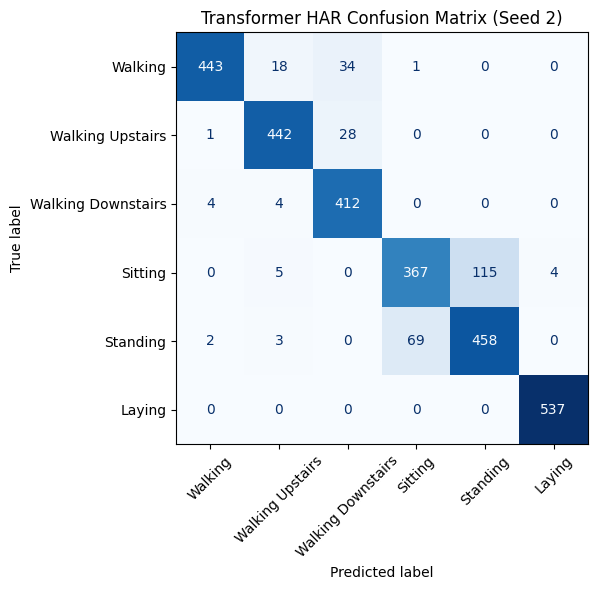

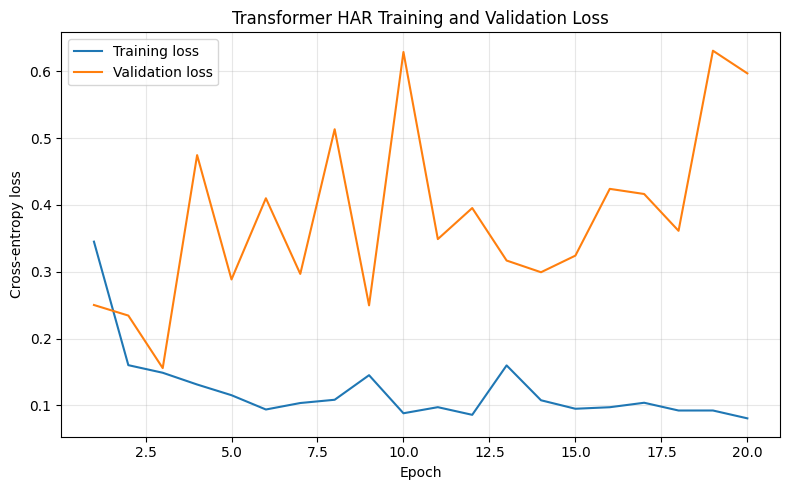


TRANSFORMER HAR EXPERIMENT COMPLETED
Results CSV: transformer_har_results.csv
Summary CSV: transformer_har_summary.csv
Confusion matrix:
transformer_har_figures/confusion_matrix.png
Learning curves:
transformer_har_figures/learning_curves.png

Use the mean test accuracy and standard deviation
from the summary table in your final report.


In [6]:

# ============================================================
# PROBLEM 2 - TASK A: TRANSFORMER HAR CLASSIFICATION
# ============================================================

import os
import time
import random
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

assert "create_har_split" in globals(), \
    "Run the HAR dataset preparation cell first."

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEEDS = (0, 1, 2)

EPOCHS = 20
BATCH_SIZE = 64
LEARNING_RATE = 0.001

INPUT_DIM = 9
D_MODEL = 128
NUM_HEADS = 4
NUM_LAYERS = 4
FF_DIM = 512
DROPOUT = 0.1
NUM_CLASSES = 6

ACTIVITY_NAMES = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

os.makedirs("transformer_har_figures", exist_ok=True)

print("Device:", DEVICE)


# ============================================================
# 2. REPRODUCIBILITY
# ============================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ============================================================
# 3. LABEL PREPARATION
# ============================================================

def prepare_labels(ytr, yva, yte):

    ytr = np.asarray(ytr).reshape(-1).astype(np.int64)
    yva = np.asarray(yva).reshape(-1).astype(np.int64)
    yte = np.asarray(yte).reshape(-1).astype(np.int64)

    unique = np.unique(
        np.concatenate([ytr, yva, yte])
    )

    if np.array_equal(unique, np.arange(1, 7)):
        ytr -= 1
        yva -= 1
        yte -= 1

    elif not np.array_equal(unique, np.arange(0, 6)):
        raise ValueError(f"Unexpected labels: {unique}")

    return ytr, yva, yte


# ============================================================
# 4. SINUSOIDAL POSITIONAL ENCODING
# ============================================================

class SinusoidalPositionalEncoding(nn.Module):

    def __init__(self, d_model, max_len=129):

        super().__init__()

        position = torch.arange(
            max_len
        ).unsqueeze(1).float()

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-np.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)

        pe[:, 0::2] = torch.sin(
            position * div_term
        )

        pe[:, 1::2] = torch.cos(
            position * div_term
        )

        pe = pe.unsqueeze(0)

        self.register_buffer("pe", pe)

    def forward(self, x):

        return x + self.pe[:, :x.size(1), :]


# ============================================================
# 5. TRANSFORMER HAR CLASSIFIER
# ============================================================

class TransformerHARClassifier(nn.Module):

    def __init__(
        self,
        input_dim=9,
        d_model=128,
        num_heads=4,
        num_layers=4,
        ff_dim=512,
        num_classes=6,
        dropout=0.1
    ):

        super().__init__()

        # Project 9 sensor channels to 128 dimensions.
        self.embedding = nn.Linear(
            input_dim,
            d_model
        )

        # Learnable CLS token.
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, d_model)
        )

        nn.init.normal_(
            self.cls_token,
            mean=0.0,
            std=0.02
        )

        # Positional encoding.
        self.positional_encoding = (
            SinusoidalPositionalEncoding(
                d_model,
                max_len=129
            )
        )

        # Pre-LayerNorm Transformer encoder.
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.final_norm = nn.LayerNorm(d_model)

        # Six activity classes.
        self.classifier = nn.Linear(
            d_model,
            num_classes
        )

    def forward(self, x):

        # x shape: (batch, 128, 9)
        x = self.embedding(x)

        batch_size = x.size(0)

        # Add CLS token.
        cls = self.cls_token.expand(
            batch_size, -1, -1
        )

        x = torch.cat(
            [cls, x],
            dim=1
        )

        # Add positional information.
        x = self.positional_encoding(x)

        # Transformer encoder.
        x = self.encoder(x)

        # Extract CLS representation.
        cls_output = x[:, 0, :]

        cls_output = self.final_norm(cls_output)

        # Classification logits.
        return self.classifier(cls_output)


# ============================================================
# 6. DATA LOADERS
# ============================================================

def make_loader(X, y, shuffle):

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.int64)

    assert X.ndim == 3
    assert X.shape[1:] == (128, 9)
    assert len(X) == len(y)

    dataset = TensorDataset(
        torch.from_numpy(X),
        torch.from_numpy(y)
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )


# ============================================================
# 7. EVALUATION
# ============================================================

@torch.no_grad()
def evaluate(model, loader, loss_fn):

    model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for xb, yb in loader:

        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        logits = model(xb)

        loss = loss_fn(logits, yb)

        total_loss += loss.item() * len(yb)

        preds = logits.argmax(dim=1)

        all_preds.append(preds.cpu())
        all_labels.append(yb.cpu())

    preds = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()

    return (
        total_loss / len(labels),
        preds,
        labels
    )


# ============================================================
# 8. TRAIN ONE TRANSFORMER MODEL
# ============================================================

def train_transformer(seed):

    print("\n" + "=" * 65)
    print(f"TRANSFORMER HAR | SEED {seed}")
    print("=" * 65)

    set_seed(seed)

    # Same split function used in Problem 1.
    Xtr, ytr, Xva, yva, Xte, yte, *_ = (
        create_har_split(seed)
    )

    ytr, yva, yte = prepare_labels(
        ytr, yva, yte
    )

    train_loader = make_loader(Xtr, ytr, True)
    val_loader = make_loader(Xva, yva, False)
    test_loader = make_loader(Xte, yte, False)

    model = TransformerHARClassifier(
        input_dim=INPUT_DIM,
        d_model=D_MODEL,
        num_heads=NUM_HEADS,
        num_layers=NUM_LAYERS,
        ff_dim=FF_DIM,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT
    ).to(DEVICE)

    params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print("Trainable parameters:", params)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    loss_fn = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0

    train_history = []
    val_history = []
    epoch_times = []

    # ---------------- TRAINING ----------------

    for epoch in range(EPOCHS):

        model.train()

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.time()

        running_loss = 0.0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            logits = model(xb)

            loss = loss_fn(logits, yb)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * len(yb)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.time() - start_time

        train_loss = (
            running_loss / len(train_loader.dataset)
        )

        val_loss, _, _ = evaluate(
            model,
            val_loader,
            loss_fn
        )

        train_history.append(train_loss)
        val_history.append(val_loss)
        epoch_times.append(elapsed)

        # Save best validation model.
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {elapsed:.2f}s"
        )

    # ---------------- TESTING ----------------

    model.load_state_dict(best_state)

    test_loss, preds, labels = evaluate(
        model,
        test_loader,
        loss_fn
    )

    accuracy = accuracy_score(labels, preds)

    macro_f1 = f1_score(
        labels,
        preds,
        average="macro",
        zero_division=0
    )

    sec_per_epoch = np.mean(epoch_times)

    print("\nTEST RESULTS")
    print("Seed:", seed)
    print("Best epoch:", best_epoch)
    print(f"Test loss: {test_loss:.4f}")
    print(f"Test accuracy: {accuracy * 100:.2f}%")
    print(f"Macro-F1: {macro_f1 * 100:.2f}%")
    print("Parameters:", params)
    print(f"Seconds per epoch: {sec_per_epoch:.2f}")

    return {
        "seed": seed,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "test_loss": test_loss,
        "params": params,
        "sec_per_epoch": sec_per_epoch,
        "best_epoch": best_epoch,
        "preds": preds,
        "labels": labels,
        "train_history": train_history,
        "val_history": val_history,
        "model_state": best_state
    }


# ============================================================
# 9. RUN THREE RANDOM SEEDS
# ============================================================

results = []

for seed in SEEDS:

    result = train_transformer(seed)

    results.append(result)


# ============================================================
# 10. RESULTS TABLE
# ============================================================

df = pd.DataFrame([
    {
        "seed": r["seed"],
        "test_accuracy": r["accuracy"],
        "macro_f1": r["macro_f1"],
        "test_loss": r["test_loss"],
        "parameters": r["params"],
        "sec_per_epoch": r["sec_per_epoch"],
        "best_epoch": r["best_epoch"]
    }
    for r in results
])

df.to_csv(
    "transformer_har_results.csv",
    index=False
)

summary = pd.DataFrame({
    "Metric": [
        "Test accuracy",
        "Macro-F1",
        "Test loss",
        "Parameters",
        "Seconds per epoch"
    ],
    "Mean": [
        df.test_accuracy.mean(),
        df.macro_f1.mean(),
        df.test_loss.mean(),
        df.parameters.mean(),
        df.sec_per_epoch.mean()
    ],
    "Std": [
        df.test_accuracy.std(ddof=1),
        df.macro_f1.std(ddof=1),
        df.test_loss.std(ddof=1),
        df.parameters.std(ddof=1),
        df.sec_per_epoch.std(ddof=1)
    ]
})

print("\n" + "=" * 65)
print("TRANSFORMER HAR SUMMARY (MEAN ± STD)")
print("=" * 65)

print(summary.to_string(index=False))

summary.to_csv(
    "transformer_har_summary.csv",
    index=False
)


# ============================================================
# 11. CONFUSION MATRIX OF BEST SEED
# ============================================================

best_result = max(
    results,
    key=lambda r: r["accuracy"]
)

cm = confusion_matrix(
    best_result["labels"],
    best_result["preds"],
    labels=range(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=ACTIVITY_NAMES
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title(
    f"Transformer HAR Confusion Matrix "
    f"(Seed {best_result['seed']})"
)

plt.tight_layout()

plt.savefig(
    "transformer_har_figures/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. LEARNING CURVES OF BEST SEED
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    range(1, EPOCHS + 1),
    best_result["train_history"],
    label="Training loss"
)

ax.plot(
    range(1, EPOCHS + 1),
    best_result["val_history"],
    label="Validation loss"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("Transformer HAR Training and Validation Loss")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "transformer_har_figures/learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 65)
print("TRANSFORMER HAR EXPERIMENT COMPLETED")
print("=" * 65)

print("Results CSV: transformer_har_results.csv")
print("Summary CSV: transformer_har_summary.csv")
print("Confusion matrix:")
print("transformer_har_figures/confusion_matrix.png")
print("Learning curves:")
print("transformer_har_figures/learning_curves.png")

print("\nUse the mean test accuracy and standard deviation")
print("from the summary table in your final report.")


Device: cuda | quick: False | parts: ['a', 'b', 'c', 'd']

=== 5(a) gradient flow, T = 100 ===
  RNN T=100 seed=0 clip=None epoch 01/30 val=0.16123
  RNN T=100 seed=0 clip=None epoch 02/30 val=0.16051
  RNN T=100 seed=0 clip=None epoch 03/30 val=0.16274
  RNN T=100 seed=0 clip=None epoch 04/30 val=0.16471
  RNN T=100 seed=0 clip=None epoch 05/30 val=0.16227
  RNN T=100 seed=0 clip=None epoch 06/30 val=0.16046
  RNN T=100 seed=0 clip=None epoch 07/30 val=0.16058
  RNN T=100 seed=0 clip=None epoch 08/30 val=0.16124
  RNN T=100 seed=0 clip=None epoch 09/30 val=0.16114
  RNN T=100 seed=0 clip=None epoch 10/30 val=0.16433
  RNN T=100 seed=0 clip=None epoch 11/30 val=0.16065
  RNN T=100 seed=0 clip=None epoch 12/30 val=0.16082
  RNN T=100 seed=0 clip=None epoch 13/30 val=0.16296
  RNN T=100 seed=0 clip=None epoch 14/30 val=0.16083
  RNN T=100 seed=0 clip=None epoch 15/30 val=0.16060
  RNN T=100 seed=0 clip=None epoch 16/30 val=0.16205
  RNN T=100 seed=0 clip=None epoch 17/30 val=0.16228
  RN

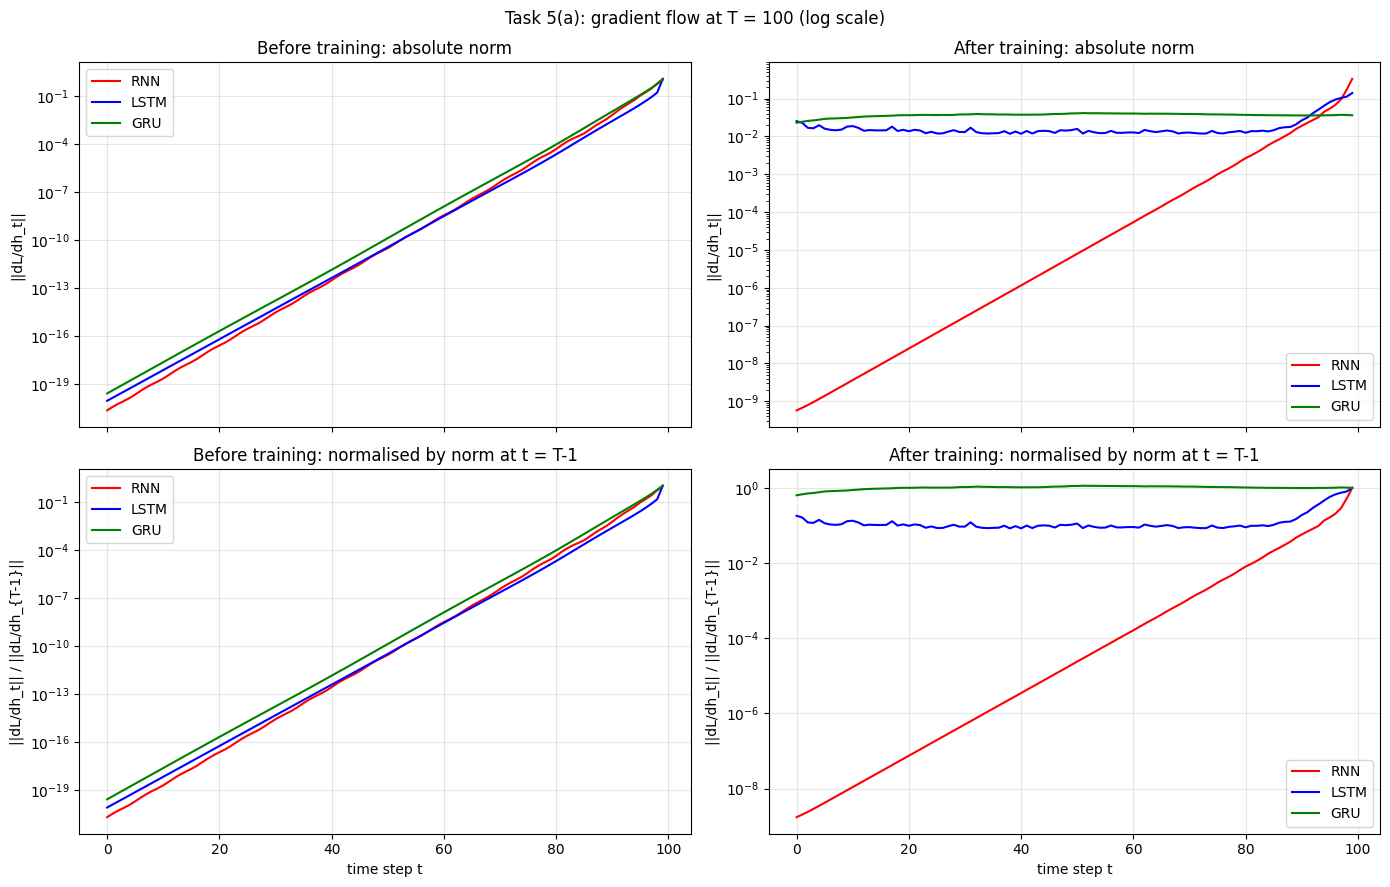

model  phase  norm_t_last   norm_t_mid  norm_t_first  log10_first_over_last
  RNN before     1.136771 3.058835e-11  2.298192e-21             -20.694288
  RNN  after     0.331038 7.940478e-06  5.771251e-10              -8.758608
 LSTM before     1.127080 3.562917e-11  9.095658e-21             -20.093121
 LSTM  after     0.140164 1.578282e-02  2.528717e-02              -0.743737
  GRU before     0.997386 1.302669e-10  2.624144e-20             -19.579876
  GRU  after     0.036203 4.069439e-02  2.299082e-02              -0.197192
model  test_mse_after  solved
  RNN        0.170553   False
 LSTM        0.006151    True
  GRU        0.000429    True
log10_first_over_last = orders of magnitude the gradient shrinks (negative) or grows (positive) over 99 steps back in time.

=== 5(b) hidden-size sweep ===
  LSTM h=16 seed=0: acc=0.8429 f1=0.8417 params=1830 0.28s/epoch
  LSTM h=16 seed=1: acc=0.7323 f1=0.7154 params=1830 0.38s/epoch
  LSTM h=16 seed=2: acc=0.8493 f1=0.8482 params=1830 0.28s/epo

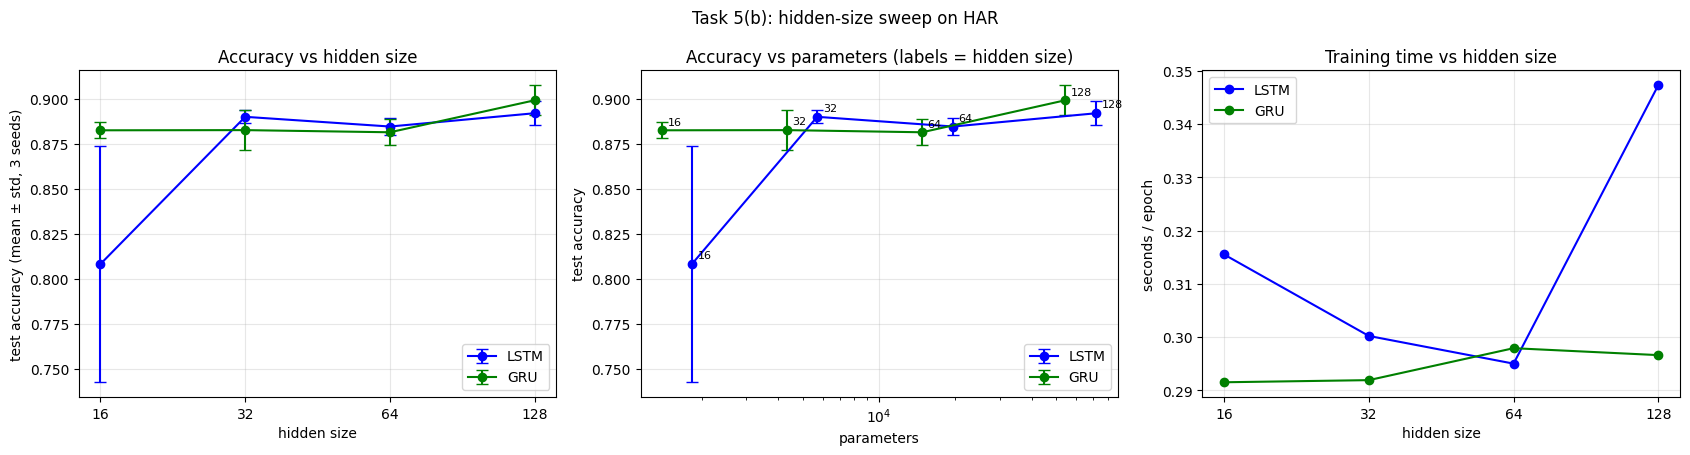


=== 5(c) gradient clipping, RNN, T = 200 ===
No clipping | seed 0
  RNN T=200 seed=0 clip=None epoch 01/30 val=0.16086
  RNN T=200 seed=0 clip=None epoch 02/30 val=0.16131
  RNN T=200 seed=0 clip=None epoch 03/30 val=0.16549
  RNN T=200 seed=0 clip=None epoch 04/30 val=0.16485
  RNN T=200 seed=0 clip=None epoch 05/30 val=0.15993
  RNN T=200 seed=0 clip=None epoch 06/30 val=0.16106
  RNN T=200 seed=0 clip=None epoch 07/30 val=0.16184
  RNN T=200 seed=0 clip=None epoch 08/30 val=0.16198
  RNN T=200 seed=0 clip=None epoch 09/30 val=0.16006
  RNN T=200 seed=0 clip=None epoch 10/30 val=0.16016
  RNN T=200 seed=0 clip=None epoch 11/30 val=0.16975
  RNN T=200 seed=0 clip=None epoch 12/30 val=0.15967
  RNN T=200 seed=0 clip=None epoch 13/30 val=0.16019
  RNN T=200 seed=0 clip=None epoch 14/30 val=0.16608
  RNN T=200 seed=0 clip=None epoch 15/30 val=0.16048
  RNN T=200 seed=0 clip=None epoch 16/30 val=0.16116
  RNN T=200 seed=0 clip=None epoch 17/30 val=0.15963
  RNN T=200 seed=0 clip=None epo

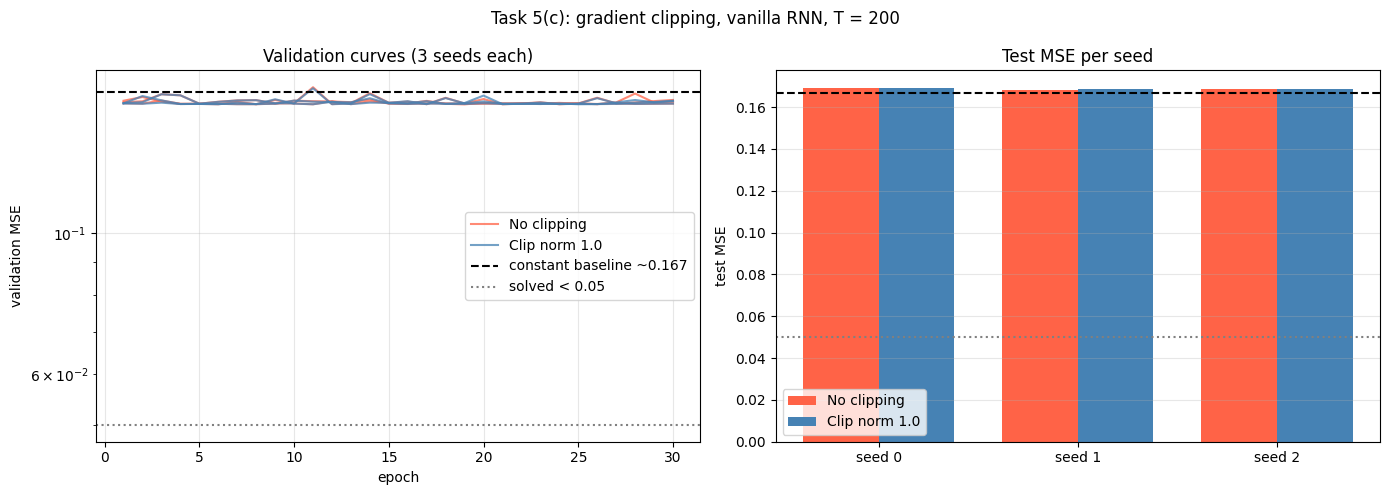


=== 5(d) tables for the analysis ===

Task 3: HAR, hidden 64 (mean ± std over 3 seeds)
model  acc_mean  acc_std  f1_mean  f1_std  params  sec_per_epoch
  GRU    0.8815   0.0073   0.8810  0.0074   14790         0.2720
 LSTM    0.8847   0.0046   0.8850  0.0053   19590         0.2929
  RNN    0.7454   0.0402   0.7385  0.0431    5190         0.2761

Task 5(b): hidden-size sweep
model  hidden  acc_mean  acc_std  f1_mean  f1_std  params  sec_per_epoch
  GRU      16    0.8826   0.0044   0.8822  0.0049    1398         0.2915
  GRU      32    0.8827   0.0110   0.8826  0.0112    4326         0.2919
  GRU      64    0.8815   0.0073   0.8810  0.0074   14790         0.2979
  GRU     128    0.8993   0.0084   0.8988  0.0084   54150         0.2966
 LSTM      16    0.8082   0.0658   0.8018  0.0748    1830         0.3155
 LSTM      32    0.8901   0.0036   0.8894  0.0042    5702         0.3002
 LSTM      64    0.8847   0.0046   0.8850  0.0053   19590         0.2950
 LSTM     128    0.8921   0.0068   0.8

In [6]:
# ============================================================
# PROBLEM 1 - TASK 5 (complete, self-contained)
# ============================================================

import os, time, random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
RUN = set(os.environ.get("T5_RUN", "a,b,c,d").split(","))
QUICK = os.environ.get("T5_QUICK", "0") == "1"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("figures", exist_ok=True)

HID = 64
ADD_BATCH, ADD_LR = 64, 1e-3
N_TRAIN = 2000 if QUICK else 10000

# (a)
GRAD_T = 100
GRAD_SEED = 0
GRAD_EPOCHS = 2 if QUICK else 30       # same budget as Task 4
GRAD_SAMPLES = 256                     # validation samples used to measure gradients

# (b)
HIDDEN_SIZES = (16, 32, 64, 128)
SWEEP_MODELS = ("LSTM", "GRU")
SWEEP_SEEDS = (0, 1, 2)
SWEEP_EPOCHS, SWEEP_BATCH, SWEEP_LR = (1 if QUICK else 20), 64, 1e-3
SWEEP_CSV = "hidden_size_sweep.csv"
SWEEP_SUMMARY = "hidden_size_summary.csv"

# (c)
ABL_T = 200
ABL_SEEDS = (0, 1, 2)
ABL_EPOCHS = 2 if QUICK else 30
CONDITIONS = {"No clipping": None, "Clip norm 1.0": 1.0}

SOLVED_MSE = 0.05
COLORS = {"RNN": "red", "LSTM": "blue", "GRU": "green"}

print("Device:", DEVICE, "| quick:", QUICK, "| parts:", sorted(RUN))


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ------------------------------------------------------------
# Fallback definitions (only used if earlier cells were not run)
# ------------------------------------------------------------
if "make_adding" not in globals():
    def make_adding(n, T, seed):
        rng = np.random.default_rng(seed)
        x = np.zeros((n, T, 2), dtype=np.float32)
        x[:, :, 0] = rng.random((n, T))
        i1 = rng.integers(0, T // 2, n)
        i2 = rng.integers(T // 2, T, n)
        x[np.arange(n), i1, 1] = 1
        x[np.arange(n), i2, 1] = 1
        y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
        return x, y.astype(np.float32)

if "b" in RUN and "create_har_split" not in globals():
    import zipfile
    _CH = ["body_acc_x", "body_acc_y", "body_acc_z", "body_gyro_x", "body_gyro_y",
           "body_gyro_z", "total_acc_x", "total_acc_y", "total_acc_z"]

    def _har_root():
        for p in ["/content/har/UCI HAR Dataset", "har/UCI HAR Dataset", "UCI HAR Dataset"]:
            if Path(p).exists():
                return Path(p)
        z = Path("/content/UCI HAR Dataset.zip")
        if z.exists():
            with zipfile.ZipFile(z) as f:
                f.extractall("/content/har")
            return Path("/content/har/UCI HAR Dataset")
        raise FileNotFoundError("UCI HAR dataset not found. Run the Task 1 cell first.")

    _ROOT = _har_root()

    def _load(split):
        sig = _ROOT / split / "Inertial Signals"
        X = np.stack([np.loadtxt(sig / f"{c}_{split}.txt", dtype=np.float32) for c in _CH], -1)
        y = np.loadtxt(_ROOT / split / f"y_{split}.txt", dtype=np.int64) - 1
        s = np.loadtxt(_ROOT / split / f"subject_{split}.txt", dtype=np.int64)
        return X, y, s

    _Xf, _yf, _sf = _load("train")
    _Xt, _yt, _ = _load("test")

    def create_har_split(seed):
        rng = np.random.default_rng(seed)
        val_subj = rng.choice(np.unique(_sf), size=4, replace=False)
        vm = np.isin(_sf, val_subj)
        Xtr, ytr, Xva, yva = _Xf[~vm], _yf[~vm], _Xf[vm], _yf[vm]
        mean, std = Xtr.mean(axis=(0, 1)), Xtr.std(axis=(0, 1))
        std = np.where(std < 1e-8, 1.0, std)
        f = lambda a: ((a - mean) / std).astype(np.float32)
        return f(Xtr), ytr, f(Xva), yva, f(_Xt), _yt, mean, std, val_subj


# ============================================================
# Shared adding-problem models and trainer (used by (a) and (c))
# ============================================================
LIB = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
CELL = {"RNN": nn.RNNCell, "LSTM": nn.LSTMCell, "GRU": nn.GRUCell}


class LibAdder(nn.Module):
    """Fast cuDNN model used for training (same as Task 4)."""
    def __init__(self, kind, hidden=HID):
        super().__init__()
        self.rnn = LIB[kind](2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1]).squeeze(-1)


class CellAdder(nn.Module):
    """Same network unrolled step by step, so that dL/dh_t exists for every t."""
    def __init__(self, kind, hidden=HID):
        super().__init__()
        self.kind, self.hidden = kind, hidden
        self.cell = CELL[kind](2, hidden)
        self.fc = nn.Linear(hidden, 1)

    def load_from(self, lib):
        with torch.no_grad():
            for n in ("weight_ih", "weight_hh", "bias_ih", "bias_hh"):
                getattr(self.cell, n).copy_(getattr(lib.rnn, n + "_l0"))
            self.fc.load_state_dict(lib.fc.state_dict())

    def forward(self, x):
        B, T, _ = x.shape
        h = x.new_zeros(B, self.hidden)
        c = x.new_zeros(B, self.hidden)
        hs = []
        for t in range(T):
            if self.kind == "LSTM":
                h, c = self.cell(x[:, t], (h, c))
            else:
                h = self.cell(x[:, t], h)
            if h.requires_grad:
                h.retain_grad()
            hs.append(h)
        return self.fc(h).squeeze(-1), hs


_ADD_CACHE = {}


def adding_tensors(T):
    if T not in _ADD_CACHE:
        parts = []
        for n, s in ((N_TRAIN, 0), (1000, 1), (1000, 2)):   # same splits as Task 4
            X, y = make_adding(n, T, s)
            parts += [torch.from_numpy(X).to(DEVICE), torch.from_numpy(y).to(DEVICE)]
        _ADD_CACHE[T] = parts
    return _ADD_CACHE[T]


def make_model(kind, seed, hidden=HID):
    seed_everything(seed)                  # identical initial weights for identical seed
    return LibAdder(kind, hidden).to(DEVICE)


@torch.no_grad()
def mse_eval(model, X, y):
    model.eval()
    se = sum(((model(X[i:i + 500]) - y[i:i + 500]) ** 2).sum().item()
             for i in range(0, len(X), 500))
    return se / len(X)


def train_adder(kind, T, seed, epochs, clip=None, hidden=HID):
    """Adam, lr 1e-3, batch 64, best-validation checkpoint (as in Task 4).
    clip=None measures the gradient norm without changing it."""
    Xtr, ytr, Xva, yva, Xte, yte = adding_tensors(T)
    model = make_model(kind, seed, hidden)
    opt = torch.optim.Adam(model.parameters(), lr=ADD_LR)
    loss_fn = nn.MSELoss()
    best_val, best_state, val_curve, norms = float("inf"), None, [], []
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr), device=DEVICE)
        for i in range(0, len(Xtr), ADD_BATCH):
            idx = perm[i:i + ADD_BATCH]
            opt.zero_grad(set_to_none=True)
            loss_fn(model(Xtr[idx]), ytr[idx]).backward()
            g = nn.utils.clip_grad_norm_(model.parameters(),
                                         float("inf") if clip is None else clip)
            norms.append(g.detach())              # pre-clipping norm
            opt.step()
        v = mse_eval(model, Xva, yva)
        val_curve.append(v)
        if v < best_val:
            best_val = v
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
        print(f"  {kind} T={T} seed={seed} clip={clip} epoch {ep + 1:02d}/{epochs} val={v:.5f}")
    model.load_state_dict(best_state)
    return dict(model=model, test_mse=mse_eval(model, Xte, yte), val_curve=val_curve,
                norms=torch.stack(norms).cpu().numpy(), seconds=time.time() - t0)


# ============================================================
# 5(a) Gradient flow:  ||dL/dh_t||  vs t, T = 100
# ============================================================
def grad_profile(lib_model, kind, X, y):
    """Mean over samples of ||dL/dh_t|| (L = per-sample squared error, so samples do not mix)."""
    cm = CellAdder(kind).to(DEVICE)
    cm.load_from(lib_model)
    cm.eval()
    with torch.no_grad():                                   # sanity: unrolled == library
        assert torch.allclose(cm(X[:8])[0], lib_model.eval()(X[:8]), atol=1e-4), \
            "unrolled model does not match library model"
    cm.zero_grad(set_to_none=True)
    pred, hs = cm(X)
    ((pred - y) ** 2).sum().backward()
    g = torch.stack([h.grad for h in hs], dim=1)            # (B, T, H)
    return g.norm(dim=2).mean(dim=0).cpu().numpy()          # (T,)


if "a" in RUN:
    print("\n=== 5(a) gradient flow, T =", GRAD_T, "===")
    Xtr, ytr, Xva, yva, Xte, yte = adding_tensors(GRAD_T)
    Xg, yg = Xva[:GRAD_SAMPLES], yva[:GRAD_SAMPLES]
    prof, info = {}, []
    for kind in ("RNN", "LSTM", "GRU"):
        before = grad_profile(make_model(kind, GRAD_SEED), kind, Xg, yg)
        r = train_adder(kind, GRAD_T, GRAD_SEED, GRAD_EPOCHS)
        after = grad_profile(r["model"], kind, Xg, yg)
        prof[kind] = dict(before=before, after=after)
        info.append(dict(model=kind, test_mse_after=r["test_mse"],
                         solved=r["test_mse"] < SOLVED_MSE))

    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
    t = np.arange(GRAD_T)
    for j, phase in enumerate(("before", "after")):
        for kind in ("RNN", "LSTM", "GRU"):
            g = np.maximum(prof[kind][phase], 1e-30)
            axes[0, j].plot(t, g, color=COLORS[kind], label=kind)
            axes[1, j].plot(t, g / g[-1], color=COLORS[kind], label=kind)
        axes[0, j].set_title(f"{phase.capitalize()} training: absolute norm")
        axes[1, j].set_title(f"{phase.capitalize()} training: normalised by norm at t = T-1")
        for i in range(2):
            axes[i, j].set_yscale("log"); axes[i, j].grid(alpha=.3); axes[i, j].legend()
            axes[i, j].set_ylabel("||dL/dh_t||" if i == 0 else "||dL/dh_t|| / ||dL/dh_{T-1}||")
        axes[1, j].set_xlabel("time step t")
    plt.suptitle(f"Task 5(a): gradient flow at T = {GRAD_T} (log scale)")
    plt.tight_layout()
    plt.savefig("figures/task5a_gradient_norm.png", dpi=300); plt.show()

    rows = []
    for kind in ("RNN", "LSTM", "GRU"):
        for phase in ("before", "after"):
            g = prof[kind][phase]
            rows.append(dict(model=kind, phase=phase, norm_t_last=g[-1], norm_t_mid=g[GRAD_T // 2],
                             norm_t_first=g[0],
                             log10_first_over_last=np.log10(max(g[0], 1e-30) / max(g[-1], 1e-30))))
    prof_df = pd.DataFrame(rows)
    prof_df.to_csv("task5a_gradient_summary.csv", index=False)
    pd.DataFrame(info).to_csv("task5a_trained_models.csv", index=False)
    print(prof_df.to_string(index=False))
    print(pd.DataFrame(info).to_string(index=False))
    print("log10_first_over_last = orders of magnitude the gradient shrinks (negative) or grows "
          "(positive) over", GRAD_T - 1, "steps back in time.")


# ============================================================
# 5(b) Hidden-size sweep on HAR (LSTM and GRU)
# ============================================================
class HARNet(nn.Module):
    def __init__(self, kind, hidden):
        super().__init__()
        self.rnn = LIB[kind](9, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 6)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1])


def _loader(X, y, shuffle):
    ds = TensorDataset(torch.from_numpy(np.asarray(X, np.float32)),
                       torch.from_numpy(np.asarray(y, np.int64)))
    return DataLoader(ds, batch_size=SWEEP_BATCH, shuffle=shuffle)


@torch.no_grad()
def _eval_har(model, loader, loss_fn):
    model.eval()
    tot, P, L = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        lg = model(xb)
        tot += loss_fn(lg, yb).item() * len(yb)
        P.append(lg.argmax(1).cpu().numpy()); L.append(yb.cpu().numpy())
    P, L = np.concatenate(P), np.concatenate(L)
    return tot / len(L), float((P == L).mean()), float(f1_score(L, P, average="macro", zero_division=0))


def run_sweep_one(kind, hidden, seed):
    seed_everything(seed)
    Xtr, ytr, Xva, yva, Xte, yte, *_ = create_har_split(seed)
    if QUICK:
        Xtr, ytr = Xtr[:640], ytr[:640]
    tr, va, te = _loader(Xtr, ytr, True), _loader(Xva, yva, False), _loader(Xte, yte, False)
    model = HARNet(kind, hidden).to(DEVICE)
    params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.Adam(model.parameters(), lr=SWEEP_LR)
    loss_fn = nn.CrossEntropyLoss()
    best, state, times = float("inf"), None, []
    for ep in range(SWEEP_EPOCHS):
        model.train()
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        for xb, yb in tr:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss_fn(model(xb), yb).backward()
            opt.step()
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        times.append(time.time() - t0)
        vl, _, _ = _eval_har(model, va, loss_fn)
        if vl < best:
            best = vl
            state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(state)
    tl, acc, f1 = _eval_har(model, te, loss_fn)
    print(f"  {kind} h={hidden} seed={seed}: acc={acc:.4f} f1={f1:.4f} params={params} "
          f"{np.mean(times):.2f}s/epoch")
    return dict(model=kind, hidden=hidden, seed=seed, accuracy=acc, macro_f1=f1,
                test_loss=tl, params=params, sec_per_epoch=float(np.mean(times)))


if "b" in RUN:
    print("\n=== 5(b) hidden-size sweep ===")
    done = pd.DataFrame()
    if Path(SWEEP_CSV).exists() and not QUICK:             # resume: keep finished runs
        done = pd.read_csv(SWEEP_CSV).drop_duplicates(["model", "hidden", "seed"], keep="last")
    rows = done.to_dict("records")
    have = {(r["model"], int(r["hidden"]), int(r["seed"])) for r in rows}
    for kind in SWEEP_MODELS:
        for h in HIDDEN_SIZES:
            for s in SWEEP_SEEDS:
                if (kind, h, s) in have:
                    continue
                rows.append(run_sweep_one(kind, h, s))
                if not QUICK:
                    pd.DataFrame(rows).to_csv(SWEEP_CSV, index=False)
    sweep = pd.DataFrame(rows)
    summ = sweep.groupby(["model", "hidden"]).agg(
        acc_mean=("accuracy", "mean"), acc_std=("accuracy", lambda x: x.std(ddof=1)),
        f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", lambda x: x.std(ddof=1)),
        params=("params", "first"), sec_per_epoch=("sec_per_epoch", "mean")).round(4)
    summ.to_csv(SWEEP_SUMMARY)
    print(summ)

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    for kind in SWEEP_MODELS:
        s = summ.loc[kind].loc[list(HIDDEN_SIZES)]
        ax[0].errorbar(HIDDEN_SIZES, s.acc_mean, yerr=s.acc_std, marker="o", capsize=4,
                       color=COLORS[kind], label=kind)
        ax[1].errorbar(s.params, s.acc_mean, yerr=s.acc_std, marker="o", capsize=4,
                       color=COLORS[kind], label=kind)
        for h, p, a in zip(HIDDEN_SIZES, s.params, s.acc_mean):
            ax[1].annotate(str(h), (p, a), textcoords="offset points", xytext=(4, 4), fontsize=8)
        ax[2].plot(HIDDEN_SIZES, s.sec_per_epoch, marker="o", color=COLORS[kind], label=kind)
    ax[0].set(xlabel="hidden size", ylabel="test accuracy (mean ± std, 3 seeds)", title="Accuracy vs hidden size")
    ax[0].set_xscale("log", base=2); ax[0].set_xticks(HIDDEN_SIZES); ax[0].set_xticklabels(HIDDEN_SIZES)
    ax[1].set(xlabel="parameters", ylabel="test accuracy", title="Accuracy vs parameters (labels = hidden size)")
    ax[1].set_xscale("log")
    ax[2].set(xlabel="hidden size", ylabel="seconds / epoch", title="Training time vs hidden size")
    ax[2].set_xscale("log", base=2); ax[2].set_xticks(HIDDEN_SIZES); ax[2].set_xticklabels(HIDDEN_SIZES)
    for a in ax: a.grid(alpha=.3); a.legend()
    plt.suptitle("Task 5(b): hidden-size sweep on HAR")
    plt.tight_layout(); plt.savefig("figures/task5b_hidden_sweep.png", dpi=300); plt.show()


# ============================================================
# 5(c) Ablation: gradient clipping (1.0 vs none), vanilla RNN, T = 200
# ============================================================
if "c" in RUN:
    print("\n=== 5(c) gradient clipping, RNN, T =", ABL_T, "===")
    rows, curves = [], {}
    for name, clip in CONDITIONS.items():
        for seed in ABL_SEEDS:
            print(f"{name} | seed {seed}")
            r = train_adder("RNN", ABL_T, seed, ABL_EPOCHS, clip=clip)
            curves[(name, seed)] = r["val_curve"]
            n = r["norms"]
            rows.append(dict(clipping=name, seed=seed, test_mse=r["test_mse"],
                             solved=r["test_mse"] < SOLVED_MSE,
                             median_grad_norm=float(np.median(n)), max_grad_norm=float(n.max()),
                             frac_steps_norm_above_1=float((n > 1.0).mean()), seconds=r["seconds"]))
    abl = pd.DataFrame(rows)
    abl.to_csv("task5c_ablation.csv", index=False)
    abl_sum = abl.groupby("clipping").agg(
        mse_mean=("test_mse", "mean"), mse_std=("test_mse", lambda x: x.std(ddof=1)),
        solved_of_3=("solved", "sum"), median_grad=("median_grad_norm", "mean"),
        max_grad=("max_grad_norm", "mean"), frac_above_1=("frac_steps_norm_above_1", "mean"),
        seconds=("seconds", "mean")).round(5)
    abl_sum.to_csv("task5c_summary.csv")
    print(abl.to_string(index=False)); print(abl_sum)

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    for (name, seed), c in curves.items():
        ax[0].plot(range(1, len(c) + 1), c, color="tomato" if name.startswith("No") else "steelblue",
                   alpha=.75, label=name if seed == ABL_SEEDS[0] else None)
    ax[0].axhline(0.167, color="k", ls="--", label="constant baseline ~0.167")
    ax[0].axhline(SOLVED_MSE, color="gray", ls=":", label="solved < 0.05")
    ax[0].set(yscale="log", xlabel="epoch", ylabel="validation MSE", title="Validation curves (3 seeds each)")
    ax[0].legend(); ax[0].grid(alpha=.3)
    w = 0.38
    for k, (name, col) in enumerate((("No clipping", "tomato"), ("Clip norm 1.0", "steelblue"))):
        v = abl[abl.clipping == name].sort_values("seed").test_mse.values
        ax[1].bar(np.arange(len(v)) + (k - .5) * w, v, w, color=col, label=name)
    ax[1].axhline(0.167, color="k", ls="--"); ax[1].axhline(SOLVED_MSE, color="gray", ls=":")
    ax[1].set(xticks=range(len(ABL_SEEDS)), xticklabels=[f"seed {s}" for s in ABL_SEEDS],
              ylabel="test MSE", title="Test MSE per seed")
    ax[1].legend(); ax[1].grid(axis="y", alpha=.3)
    plt.suptitle(f"Task 5(c): gradient clipping, vanilla RNN, T = {ABL_T}")
    plt.tight_layout(); plt.savefig("figures/task5c_gradient_clipping.png", dpi=300); plt.show()


# ============================================================
# 5(d) Tables for the one-page analysis
# ============================================================
if "d" in RUN:
    print("\n=== 5(d) tables for the analysis ===")
    for f, title in (("har_summary.csv", "Task 3: HAR, hidden 64 (mean ± std over 3 seeds)"),
                     ("adding_summary.csv", "Task 4: adding problem test MSE"),
                     ("adding_solved_counts.csv", "Task 4: solved runs out of 3"),
                     (SWEEP_SUMMARY, "Task 5(b): hidden-size sweep"),
                     ("task5c_summary.csv", "Task 5(c): clipping ablation")):
        if Path(f).exists():
            print("\n" + title); print(pd.read_csv(f).to_string(index=False))
    rows = []
    for T in (50, 100, 200, 400):
        _, ytr_ = make_adding(N_TRAIN, T, 0)
        _, yte_ = make_adding(1000, T, 2)
        rows.append(dict(T=T, baseline_mse=float(np.mean((yte_ - ytr_.mean()) ** 2))))
    base = pd.DataFrame(rows)
    base.to_csv("adding_baselines.csv", index=False)
    print("\nConstant-prediction baseline (train mean, evaluated on each test set):")
    print(base.round(4).to_string(index=False))

print("\nTask 5 finished. Figures in ./figures, tables in the working directory.")

Device: cuda

Training RNN | Sequence length: 50
Epoch 01/20 | Train MSE: 0.199385 | Val MSE: 0.173717
Epoch 02/20 | Train MSE: 0.167343 | Val MSE: 0.177452
Epoch 03/20 | Train MSE: 0.167712 | Val MSE: 0.176781
Epoch 04/20 | Train MSE: 0.167256 | Val MSE: 0.173358
Epoch 05/20 | Train MSE: 0.167040 | Val MSE: 0.180408
Epoch 06/20 | Train MSE: 0.167299 | Val MSE: 0.172709
Epoch 07/20 | Train MSE: 0.167427 | Val MSE: 0.174304
Epoch 08/20 | Train MSE: 0.168270 | Val MSE: 0.177023
Epoch 09/20 | Train MSE: 0.166685 | Val MSE: 0.172666
Epoch 10/20 | Train MSE: 0.166868 | Val MSE: 0.173778
Epoch 11/20 | Train MSE: 0.166916 | Val MSE: 0.172934
Epoch 12/20 | Train MSE: 0.166254 | Val MSE: 0.172593
Epoch 13/20 | Train MSE: 0.166657 | Val MSE: 0.171874
Epoch 14/20 | Train MSE: 0.166792 | Val MSE: 0.173658
Epoch 15/20 | Train MSE: 0.165908 | Val MSE: 0.172262
Epoch 16/20 | Train MSE: 0.165808 | Val MSE: 0.173541
Epoch 17/20 | Train MSE: 0.165662 | Val MSE: 0.170038
Epoch 18/20 | Train MSE: 0.164565

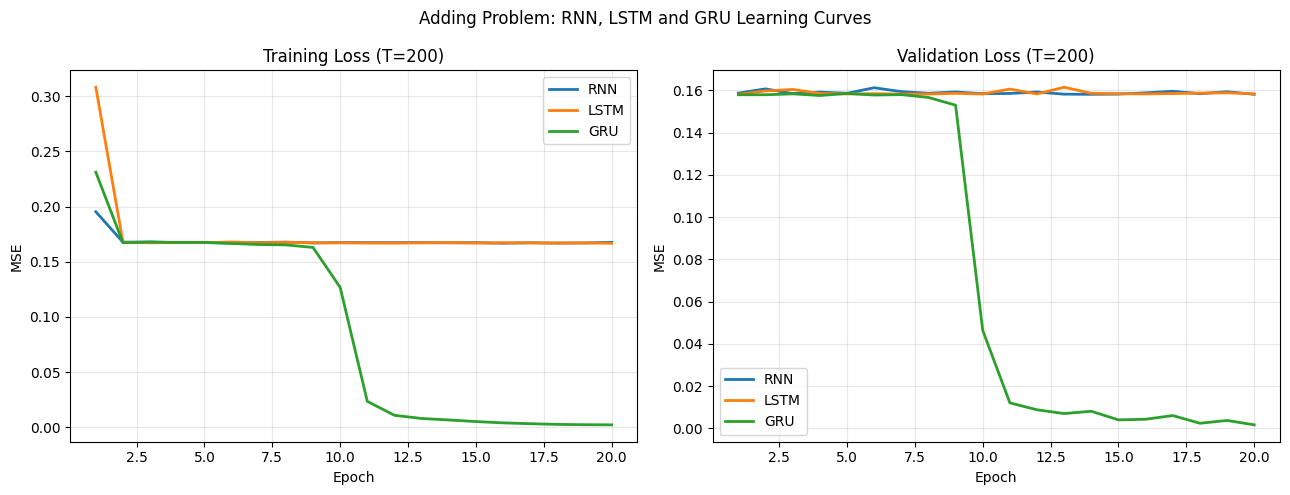

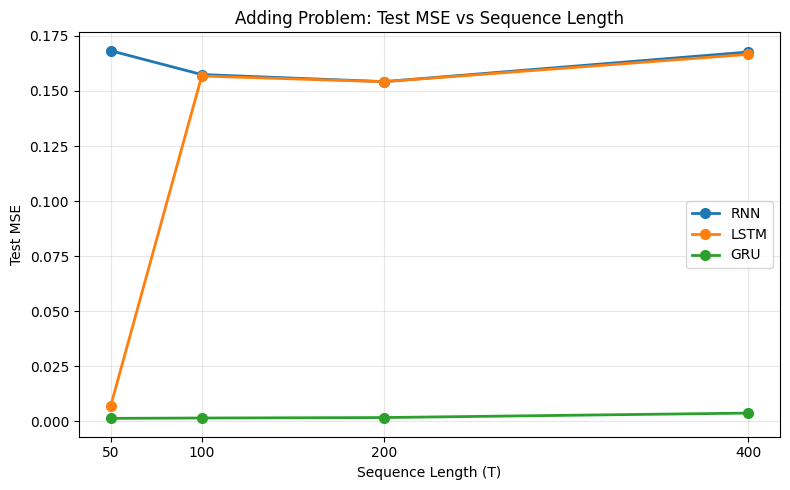


ADDING PROBLEM RESULTS
Model                 GRU      LSTM       RNN
Sequence Length                              
50               0.001257  0.006851  0.168296
100              0.001403  0.156789  0.157467
200              0.001610  0.154219  0.154253
400              0.003640  0.166633  0.167692

EXPERIMENT COMPLETED
Figure 3: figures/figure3_adding_learning_curves.png
Figure 4: figures/figure4_adding_test_mse.png
Results: adding_problem_results.csv


In [7]:

# ============================================================
# PROBLEM 1: Additional
# ============================================================

import os
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader

# ---------------- CONFIGURATION ----------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEQUENCE_LENGTHS = [50, 100, 200, 400]
MODELS = ["RNN", "LSTM", "GRU"]

HIDDEN = 64
BATCH_SIZE = 64
EPOCHS = 20
LR = 0.001

TRAIN_SIZE = 10000
VAL_SIZE = 1000
TEST_SIZE = 1000

SEED = 42

os.makedirs("figures", exist_ok=True)

print("Device:", DEVICE)


# ---------------- REPRODUCIBILITY ----------------

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ---------------- DATA GENERATION ----------------

def generate_adding_data(n, seq_len):
    """
    Input:
      Channel 1: random values
      Channel 2: two binary markers

    Target: sum of the two selected values.
    """

    values = np.random.rand(n, seq_len, 1).astype(np.float32)

    markers = np.zeros((n, seq_len, 1), dtype=np.float32)

    targets = np.zeros((n, 1), dtype=np.float32)

    for i in range(n):

        positions = np.random.choice(
            seq_len, 2, replace=False
        )

        markers[i, positions, 0] = 1.0

        targets[i, 0] = values[
            i, positions, 0
        ].sum()

    X = np.concatenate(
        [values, markers], axis=2
    )

    return X, targets


# ---------------- MODEL ----------------

class AddingModel(nn.Module):

    def __init__(self, model_type, hidden=64):

        super().__init__()

        rnn_class = {
            "RNN": nn.RNN,
            "LSTM": nn.LSTM,
            "GRU": nn.GRU
        }[model_type]

        self.rnn = rnn_class(
            input_size=2,
            hidden_size=hidden,
            batch_first=True
        )

        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):

        output, _ = self.rnn(x)

        last_output = output[:, -1, :]

        return self.fc(last_output)


# ---------------- DATA LOADERS ----------------

def make_loader(X, y, shuffle):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32)
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle
    )


# ---------------- EVALUATION ----------------

@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    total_loss = 0
    total = 0

    for xb, yb in loader:

        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        predictions = model(xb)

        loss = nn.functional.mse_loss(
            predictions, yb, reduction="sum"
        )

        total_loss += loss.item()
        total += len(yb)

    return total_loss / total


# ---------------- TRAINING ----------------

def train_model(model_type, seq_len, seed):

    set_seed(seed)

    print(
        f"\nTraining {model_type} | "
        f"Sequence length: {seq_len}"
    )

    X_train, y_train = generate_adding_data(
        TRAIN_SIZE, seq_len
    )

    X_val, y_val = generate_adding_data(
        VAL_SIZE, seq_len
    )

    X_test, y_test = generate_adding_data(
        TEST_SIZE, seq_len
    )

    train_loader = make_loader(
        X_train, y_train, True
    )

    val_loader = make_loader(
        X_val, y_val, False
    )

    test_loader = make_loader(
        X_test, y_test, False
    )

    model = AddingModel(
        model_type, HIDDEN
    ).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=LR
    )

    criterion = nn.MSELoss()

    train_history = []
    val_history = []

    best_val = float("inf")
    best_state = None

    # Training loop

    for epoch in range(EPOCHS):

        model.train()

        total_loss = 0
        total = 0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            predictions = model(xb)

            loss = criterion(predictions, yb)

            loss.backward()

            optimizer.step()

            total_loss += loss.item() * len(yb)
            total += len(yb)

        train_loss = total_loss / total

        val_loss = evaluate(
            model, val_loader
        )

        train_history.append(train_loss)
        val_history.append(val_loss)

        if val_loss < best_val:

            best_val = val_loss

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f}"
        )

    # Restore best validation checkpoint

    model.load_state_dict(best_state)

    test_mse = evaluate(model, test_loader)

    print("Test MSE:", round(test_mse, 6))

    return {
        "train": train_history,
        "val": val_history,
        "test_mse": test_mse
    }


# ============================================================
# RUN ALL EXPERIMENTS
# ============================================================

results = {}

for seq_len in SEQUENCE_LENGTHS:

    for model_type in MODELS:

        result = train_model(
            model_type,
            seq_len,
            SEED
        )

        results[(model_type, seq_len)] = result


# ============================================================
# LEARNING CURVES AT T = 200
# ============================================================

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5)
)

for model_type in MODELS:

    result = results[(model_type, 200)]

    axes[0].plot(
        range(1, EPOCHS + 1),
        result["train"],
        label=model_type,
        linewidth=2
    )

    axes[1].plot(
        range(1, EPOCHS + 1),
        result["val"],
        label=model_type,
        linewidth=2
    )

axes[0].set_title("Training Loss (T=200)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation Loss (T=200)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Adding Problem: RNN, LSTM and GRU Learning Curves"
)

plt.tight_layout()

plt.savefig(
    "figures/figure3_adding_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# TEST MSE AGAINST SEQUENCE LENGTH
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

for model_type in MODELS:

    mse_values = [
        results[(model_type, T)]["test_mse"]
        for T in SEQUENCE_LENGTHS
    ]

    ax.plot(
        SEQUENCE_LENGTHS,
        mse_values,
        marker="o",
        linewidth=2,
        markersize=7,
        label=model_type
    )

ax.set_xlabel("Sequence Length (T)")
ax.set_ylabel("Test MSE")
ax.set_title("Adding Problem: Test MSE vs Sequence Length")

ax.set_xticks(SEQUENCE_LENGTHS)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

plt.savefig(
    "figures/figure4_adding_test_mse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE RESULTS TABLE
# ============================================================

rows = []

for (model_type, seq_len), result in results.items():

    rows.append({
        "Model": model_type,
        "Sequence Length": seq_len,
        "Test MSE": result["test_mse"]
    })

df = pd.DataFrame(rows)

print("\nADDING PROBLEM RESULTS")
print(df.pivot(
    index="Sequence Length",
    columns="Model",
    values="Test MSE"
).round(6))

df.to_csv(
    "adding_problem_results.csv",
    index=False
)

print("\nEXPERIMENT COMPLETED")
print("Figure 3: figures/figure3_adding_learning_curves.png")
print("Figure 4: figures/figure4_adding_test_mse.png")
print("Results: adding_problem_results.csv")


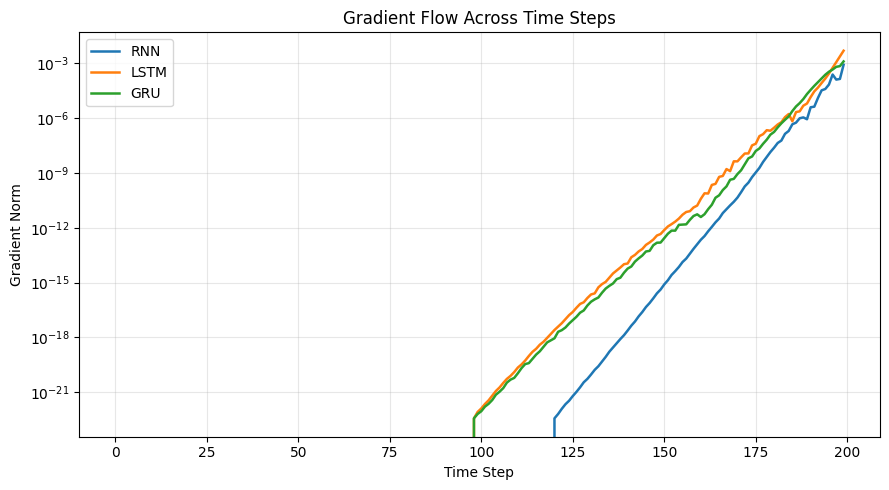


LSTM | Hidden size 16
Test accuracy: 84.8

LSTM | Hidden size 32
Test accuracy: 85.75

LSTM | Hidden size 64
Test accuracy: 88.84

LSTM | Hidden size 128
Test accuracy: 88.16

GRU | Hidden size 16
Test accuracy: 86.02

GRU | Hidden size 32
Test accuracy: 88.84

GRU | Hidden size 64
Test accuracy: 87.61

GRU | Hidden size 128
Test accuracy: 89.01

HIDDEN SIZE RESULTS
Model  Hidden size  Accuracy
 LSTM           16 84.798100
 LSTM           32 85.748219
 LSTM           64 88.836105
 LSTM          128 88.157448
  GRU           16 86.019681
  GRU           32 88.836105
  GRU           64 87.614523
  GRU          128 89.005769


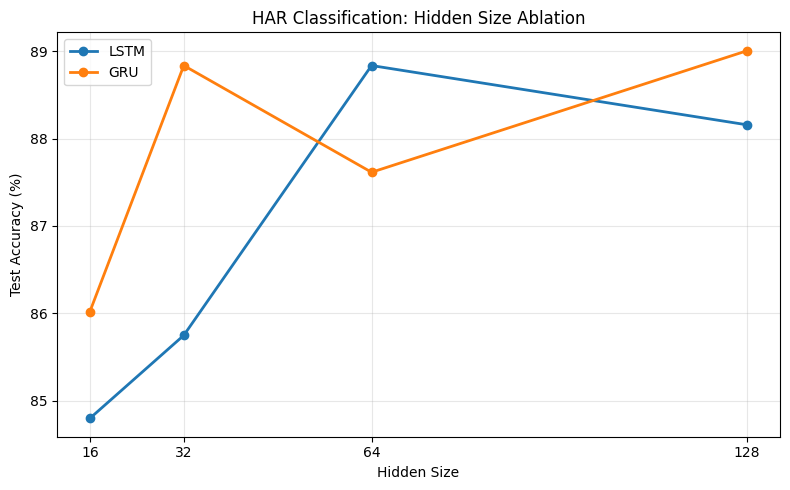


GRADIENT CLIPPING RESULTS
Configuration  Mean MSE  Std MSE
  No clipping  0.164496 0.003684
Clip norm 1.0  0.164329 0.003782


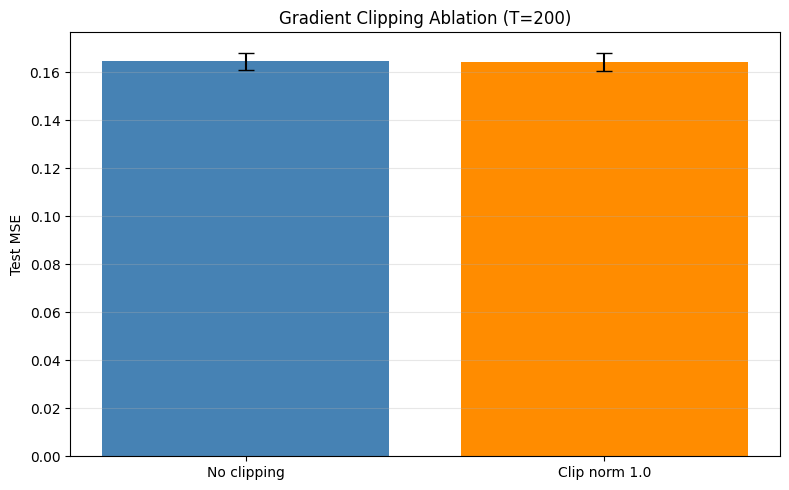


ALL THREE FIGURES GENERATED
Figure 5: figures/figure5_gradient_norm.png
Figure 6: figures/figure6_hidden_size.png
Figure 7: figures/figure7_gradient_clipping.png


In [8]:

# ============================================================
# PROBLEM 1: FIGURES 5, 6 AND 7
# ============================================================

import os
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

os.makedirs("figures", exist_ok=True)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ============================================================
# FIGURE 5: GRADIENT NORMS ACROSS TIME STEPS
# ============================================================

class GradientRNN(nn.Module):

    def __init__(self, kind, hidden=64):

        super().__init__()

        cls = {
            "RNN": nn.RNN,
            "LSTM": nn.LSTM,
            "GRU": nn.GRU
        }[kind]

        self.rnn = cls(
            input_size=2,
            hidden_size=hidden,
            batch_first=True
        )

        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):

        out, _ = self.rnn(x)

        return self.fc(out[:, -1, :])


def calculate_gradient_norms(kind, seq_len=200):

    set_seed(42)

    model = GradientRNN(kind).to(DEVICE)

    x = torch.randn(
        1, seq_len, 2,
        device=DEVICE,
        requires_grad=True
    )

    output = model(x)

    loss = output.square().mean()

    loss.backward()

    # Gradient magnitude for each input time step
    norms = torch.norm(
        x.grad.detach()[0], dim=1
    ).cpu().numpy()

    return norms


plt.figure(figsize=(9, 5))

for kind in ["RNN", "LSTM", "GRU"]:

    norms = calculate_gradient_norms(kind, 200)

    plt.plot(
        np.arange(200),
        norms,
        label=kind,
        linewidth=1.8
    )

plt.xlabel("Time Step")
plt.ylabel("Gradient Norm")
plt.title("Gradient Flow Across Time Steps")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/figure5_gradient_norm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 6: HAR HIDDEN SIZE ABLATION
# ============================================================

assert "create_har_split" in globals(), (
    "Run your HAR data preparation cell first."
)

HIDDEN_SIZES = [16, 32, 64, 128]
MODELS = ["LSTM", "GRU"]

EPOCHS = 20
BATCH = 64
LR = 0.001


def prepare_har(seed):

    out = create_har_split(seed)

    Xtr, ytr, Xva, yva, Xte, yte = out[:6]

    ytr = np.asarray(ytr).reshape(-1).astype(np.int64)
    yva = np.asarray(yva).reshape(-1).astype(np.int64)
    yte = np.asarray(yte).reshape(-1).astype(np.int64)

    if set(np.unique(ytr)) == set(range(1, 7)):
        ytr -= 1
        yva -= 1
        yte -= 1

    return Xtr, ytr, Xva, yva, Xte, yte


def loader(X, y, shuffle=False):

    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )

    return DataLoader(
        dataset,
        batch_size=BATCH,
        shuffle=shuffle
    )


class HARModel(nn.Module):

    def __init__(self, kind, hidden):

        super().__init__()

        cls = {
            "LSTM": nn.LSTM,
            "GRU": nn.GRU
        }[kind]

        self.rnn = cls(
            input_size=9,
            hidden_size=hidden,
            batch_first=True
        )

        self.fc = nn.Linear(hidden, 6)

    def forward(self, x):

        out, _ = self.rnn(x)

        return self.fc(out[:, -1, :])


def train_har(kind, hidden, seed=42):

    set_seed(seed)

    Xtr, ytr, Xva, yva, Xte, yte = prepare_har(seed)

    tr = loader(Xtr, ytr, True)
    va = loader(Xva, yva)
    te = loader(Xte, yte)

    model = HARModel(kind, hidden).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=LR
    )

    criterion = nn.CrossEntropyLoss()

    best_loss = float("inf")
    best_state = None

    for epoch in range(EPOCHS):

        model.train()

        for xb, yb in tr:

            xb, yb = xb.to(DEVICE), yb.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            loss = criterion(model(xb), yb)

            loss.backward()
            optimizer.step()

        model.eval()

        val_loss = 0
        count = 0

        with torch.no_grad():

            for xb, yb in va:

                xb, yb = xb.to(DEVICE), yb.to(DEVICE)

                loss = criterion(model(xb), yb)

                val_loss += loss.item() * len(yb)
                count += len(yb)

        val_loss /= count

        if val_loss < best_loss:

            best_loss = val_loss

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

    model.load_state_dict(best_state)
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for xb, yb in te:

            xb, yb = xb.to(DEVICE), yb.to(DEVICE)

            predictions = model(xb).argmax(1)

            correct += (predictions == yb).sum().item()
            total += len(yb)

    return correct / total


hidden_results = []

for kind in MODELS:

    for hidden in HIDDEN_SIZES:

        print(f"\n{kind} | Hidden size {hidden}")

        accuracy = train_har(
            kind, hidden, seed=42
        )

        print("Test accuracy:", round(accuracy * 100, 2))

        hidden_results.append({
            "Model": kind,
            "Hidden size": hidden,
            "Accuracy": accuracy * 100
        })


hidden_df = pd.DataFrame(hidden_results)

print("\nHIDDEN SIZE RESULTS")
print(hidden_df.to_string(index=False))

hidden_df.to_csv(
    "har_hidden_size_results.csv",
    index=False
)


plt.figure(figsize=(8, 5))

for kind in MODELS:

    subset = hidden_df[
        hidden_df["Model"] == kind
    ]

    plt.plot(
        subset["Hidden size"],
        subset["Accuracy"],
        marker="o",
        linewidth=2,
        label=kind
    )

plt.xlabel("Hidden Size")
plt.ylabel("Test Accuracy (%)")
plt.title("HAR Classification: Hidden Size Ablation")

plt.xticks(HIDDEN_SIZES)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/figure6_hidden_size.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 7: GRADIENT CLIPPING ABLATION AT T=200
# ============================================================

def generate_data(n, seq_len):

    values = np.random.rand(
        n, seq_len, 1
    ).astype(np.float32)

    markers = np.zeros(
        (n, seq_len, 1),
        dtype=np.float32
    )

    targets = np.zeros(
        (n, 1),
        dtype=np.float32
    )

    for i in range(n):

        positions = np.random.choice(
            seq_len, 2, replace=False
        )

        markers[i, positions, 0] = 1

        targets[i, 0] = values[
            i, positions, 0
        ].sum()

    return np.concatenate(
        [values, markers], axis=2
    ), targets


def clipping_experiment(clip, seed):

    set_seed(seed)

    np.random.seed(seed)

    Xtr, ytr = generate_data(10000, 200)
    Xva, yva = generate_data(1000, 200)
    Xte, yte = generate_data(1000, 200)

    tr = loader_adding(Xtr, ytr, True)
    te = loader_adding(Xte, yte, False)

    model = GradientRNN("RNN", 64).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )

    criterion = nn.MSELoss()

    history = []

    for epoch in range(20):

        model.train()

        for xb, yb in tr:

            xb, yb = xb.to(DEVICE), yb.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            loss = criterion(model(xb), yb)

            loss.backward()

            if clip:
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )

            optimizer.step()

        history.append(evaluate_adding(model, te))

    return history, history[-1]


def loader_adding(X, y, shuffle):

    return DataLoader(
        TensorDataset(
            torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32)
        ),
        batch_size=64,
        shuffle=shuffle
    )


@torch.no_grad()
def evaluate_adding(model, data_loader):

    model.eval()

    total = 0
    count = 0

    for xb, yb in data_loader:

        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        loss = nn.functional.mse_loss(
            model(xb), yb, reduction="sum"
        )

        total += loss.item()
        count += len(yb)

    return total / count


SEEDS = [0, 1, 2]

clip_results = {}

for name, clipping in [
    ("No clipping", False),
    ("Clip norm 1.0", True)
]:

    scores = []

    for seed in SEEDS:

        history, score = clipping_experiment(
            clipping, seed
        )

        scores.append(score)

    clip_results[name] = scores


clip_df = pd.DataFrame([
    {
        "Configuration": name,
        "Mean MSE": np.mean(scores),
        "Std MSE": np.std(scores, ddof=1)
    }
    for name, scores in clip_results.items()
])

print("\nGRADIENT CLIPPING RESULTS")
print(clip_df.to_string(index=False))

clip_df.to_csv(
    "gradient_clipping_results.csv",
    index=False
)


plt.figure(figsize=(8, 5))

names = list(clip_results.keys())

means = [
    np.mean(clip_results[name])
    for name in names
]

stds = [
    np.std(clip_results[name], ddof=1)
    for name in names
]

plt.bar(
    names,
    means,
    yerr=stds,
    capsize=6,
    color=["steelblue", "darkorange"]
)

plt.ylabel("Test MSE")
plt.title("Gradient Clipping Ablation (T=200)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/figure7_gradient_clipping.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# COMPLETION
# ============================================================

print("\nALL THREE FIGURES GENERATED")
print("Figure 5: figures/figure5_gradient_norm.png")
print("Figure 6: figures/figure6_hidden_size.png")
print("Figure 7: figures/figure7_gradient_clipping.png")
